# Polymer Property Prediction — Exploratory Data Analysis

## Purpose

Understand the polymer dataset before cleaning, feature engineering
and predictive modelling.

## Research question

What information does the dataset contain, how reliable is it,
and which polymer properties can we model using the available labels?

## Data files

- train.csv
- test.csv
- sample_submission.csv
- dataset1.csv
- dataset2.csv
- dataset3.csv
- dataset4.csv

## Questions to investigate

1. What does one row represent?
2. How were the property values generated?
3. What are the units and simulation conditions?
4. Which targets are available for each structure?
5. Are structures duplicated within or across files?
6. Can we process the polymer SMILES consistently?
7. Are the supplementary datasets comparable to the main dataset?

## Analysis principles

- Preserve the original files.
- Do not impute missing target values.
- Investigate unusual values before removing them.
- Record sample sizes for every comparison.
- Separate observations, hypotheses and decisions.
- Keep the final evaluation set separate from model development.

> **Note:** This notebook continues `01_mohamed_initial_eda.ipynb`.
>
> | Sections | Content | Author |
> |---|---|---|
> | 1–16 | Exploratory data analysis | Mohamed |
> | 17 | Feature engineering: molecular descriptors | Suhmi (from `02_Suhmi_Featureengineering.ipynb`), integrated and validated by Mohamed |
> | 18–19 | Target-specific datasets and validation splits | Suhmi (from `02_Suhmi_Featureengineering.ipynb`), integrated by Mohamed |
> | 20.1 | FFV median baseline | Mohamed |
> | 20.2–20.7 | Model development and evaluation | Suhmi |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("pandas version:", pd.__version__)
print("Working directory:", Path.cwd())

Python executable: C:\Users\ghsm0\Desktop\Bootcamp_DS_desktop\Capstone\capstone_virtual_lab_mohamed_suhmi\.venv\Scripts\python.exe
Python version: 3.13.14
pandas version: 3.0.5
Working directory: C:\Users\ghsm0\Desktop\Bootcamp_DS_desktop\Capstone\capstone_virtual_lab_mohamed_suhmi\notebooks


Checking the data folder. Our notebook operates within the `notebooks` subfolder. Therefore, we first move up one level to the project folder.

Pseudocode:

1- Determine the current working directory. (Aktuellen Arbeitsordner ermitteln.)

2- Identify the parent project folder. (Übergeordneten Projektordner bestimmen.)

3- Construct the path to the `data` folder. (Den Pfad zum Ordner data bilden.)

4- Check if this folder exists. (Prüfen, ob dieser Ordner existiert.)

5- List existing CSV files. (Vorhandene CSV-Dateien auflisten.)

In [2]:
# Locate the project and data directories
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.is_dir())

# List CSV files, including files in subdirectories
csv_files = sorted(DATA_DIR.rglob("*.csv"))

print("Number of CSV files:", len(csv_files))

for file_path in csv_files:
    print(file_path.relative_to(PROJECT_ROOT))
    

Project root: C:\Users\ghsm0\Desktop\Bootcamp_DS_desktop\Capstone\capstone_virtual_lab_mohamed_suhmi
Data directory: C:\Users\ghsm0\Desktop\Bootcamp_DS_desktop\Capstone\capstone_virtual_lab_mohamed_suhmi\data
Data directory exists: True
Number of CSV files: 18
data\dataset1.csv
data\dataset2.csv
data\dataset3.csv
data\dataset4.csv
data\raw\sample_submission.csv
data\raw\test.csv
data\raw\train.csv
data\raw\train_supplement\dataset1.csv
data\raw\train_supplement\dataset2.csv
data\raw\train_supplement\dataset3.csv
data\raw\train_supplement\dataset4.csv
data\sample_submission.csv
data\test.csv
data\train.csv
data\train_supplement\dataset1.csv
data\train_supplement\dataset2.csv
data\train_supplement\dataset3.csv
data\train_supplement\dataset4.csv


## 2. Dataset inventory

Before analysing individual datasets, we inspect all seven CSV files.

For each file, we record:
- its relative path;
- the number of rows and columns;
- the column names.

This provides an overview of the available data and its structure.

| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `datasets = {}` | Ein leeres Dictionary speichert die eingelesenen Tabellen. | An empty dictionary stores the loaded tables. |
| `inventory_rows = []` | Eine leere Liste sammelt die Angaben für unsere Übersicht. | An empty list collects the information for our overview. |
| `for file_path in csv_files:` | Bearbeitet jede der sieben gefundenen Dateien. | Processes each of the seven files found. |
| `.relative_to(DATA_DIR)` | Kürzt den Pfad auf den Teil innerhalb von `data`. | Makes the path relative to the `data` directory. |
| `.as_posix()` | Verwendet `/` im Pfad, damit die Bezeichnungen unter Windows und Linux gleich aussehen. | Uses `/` in the path so that the labels look the same on Windows and Linux. |
| `pd.read_csv(file_path)` | Liest die CSV-Datei als pandas-DataFrame ein. | Reads the CSV file into a pandas DataFrame. |
| `datasets[relative_path] = df` | Speichert die Tabelle unter ihrem Dateipfad für spätere Analysen. | Stores the table under its file path for later analysis. |
| `df.shape[0]` | Anzahl der Zeilen. | Number of rows. |
| `df.shape[1]` | Anzahl der Spalten. | Number of columns. |
| `", ".join(df.columns)` | Verbindet die Spaltennamen zu einem lesbaren Text. | Joins the column names into a readable string. |
| `inventory_rows.append({...})` | Fügt die Angaben einer Datei zur Übersicht hinzu. | Adds the information for one file to the overview. |
| `pd.DataFrame(inventory_rows)` | Wandelt die gesammelten Angaben in eine Tabelle um. | Converts the collected information into a table. |

In [3]:
# Load the CSV files and collect their basic structure
datasets = {}
inventory_rows = []

for file_path in csv_files:
    relative_path = file_path.relative_to(DATA_DIR).as_posix()
    df = pd.read_csv(file_path)

    datasets[relative_path] = df

    inventory_rows.append({
        "file": relative_path,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "column_names": ", ".join(df.columns),
    })

# Display the dataset inventory
inventory = pd.DataFrame(inventory_rows)
display(inventory)

,file,rows,columns,column_names
0,dataset1.csv,874,2,"SMILES, TC_mean"
1,dataset2.csv,7208,1,SMILES
2,dataset3.csv,46,2,"SMILES, Tg"
3,dataset4.csv,862,2,"SMILES, FFV"
4,raw/sample_submission.csv,3,6,"id, Tg, FFV, Tc, Density, Rg"
5,raw/test.csv,3,2,"id, SMILES"
6,raw/train.csv,7973,7,"id, SMILES, Tg, FFV, Tc, Density, Rg"
7,raw/train_supplement/dataset1.csv,874,2,"SMILES, TC_mean"
8,raw/train_supplement/dataset2.csv,7208,1,SMILES
9,raw/train_supplement/dataset3.csv,46,2,"SMILES, Tg"


## 3. Initial inspection of the training dataset

We inspect the first five rows, column data types and non-null counts.

Questions:
- Which columns contain identifiers, structures and prediction targets?
- Which data types did pandas infer?
- Which columns contain missing values?

At this stage, we do not modify or remove any observations.

## 3. Erste Untersuchung des Trainingsdatensatzes

Wir untersuchen die ersten fünf Zeilen, die Datentypen der Spalten sowie die Anzahl der Nicht-Null-Werte.

Fragen:
- Welche Spalten enthalten Identifikatoren, Strukturen und Zielvariablen?
- Welche Datentypen hat pandas abgeleitet?
- Welche Spalten enthalten fehlende Werte?

In dieser Phase verändern oder entfernen wir keine Beobachtungen.

In [4]:
# Select the training dataset already loaded into memory (Wähle den bereits in den Arbeitsspeicher geladenen Trainingsdatensatz aus)
train = datasets["raw/train.csv"]

# Display the first five rows
display(train.head())

# Inspect column data types and non-null counts
train.info()

,id,SMILES,Tg,FFV,Tc,Density,Rg
0,87817,*CC(*)c1ccccc1C(=O)OCCCCCC,NaN,0.374645,0.205667,NaN,NaN
1,106919,*Nc1ccc([C@H](CCC)c2ccc(C3(c4ccc([C@@H](CCC)c5...,NaN,0.370410,NaN,NaN,NaN
2,388772,*Oc1ccc(S(=O)(=O)c2ccc(Oc3ccc(C4(c5ccc(Oc6ccc(...,NaN,0.378860,NaN,NaN,NaN
3,519416,*Nc1ccc(-c2c(-c3ccc(C)cc3)c(-c3ccc(C)cc3)c(N*)...,NaN,0.387324,NaN,NaN,NaN
4,539187,*Oc1ccc(OC(=O)c2cc(OCCCCCCCCCOCC3CCCN3c3ccc([N...,NaN,0.355470,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 7973 entries, 0 to 7972
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       7973 non-null   int64  
 1   SMILES   7973 non-null   str    
 2   Tg       511 non-null    float64
 3   FFV      7030 non-null   float64
 4   Tc       737 non-null    float64
 5   Density  613 non-null    float64
 6   Rg       614 non-null    float64
dtypes: float64(5), int64(1), str(1)
memory usage: 436.2 KB


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `datasets` | Dictionary mit den bereits eingelesenen Tabellen. | Dictionary containing the tables already loaded. |
| `["raw/train.csv"]` | Wählt die Tabelle mit diesem Schlüssel aus dem Dictionary aus. | Selects the table with this key from the dictionary. |
| `train = ...` | Macht diese Tabelle unter dem Variablennamen `train` verfügbar. | Makes this table available under the variable name `train`. |
| `train.head()` | Gibt standardmäßig die ersten fünf Zeilen zurück. | Returns the first five rows by default. |
| `display(...)` | Zeigt das Ergebnis als Tabelle im Notebook an. | Displays the result as a table in the notebook. |
| `train.info()` | Zeigt Spaltennamen, Datentypen, Anzahl vorhandener Werte und Speicherverbrauch. | Shows column names, data types, non-null counts and memory usage. |

## 4. Missing-value analysis

We calculate the number and percentage of missing values in each column.

Missing target values are not replaced with zero or imputed.
Rows with partially available targets are preserved because they may
still be useful for predicting individual properties.

Pseudocode:
1. Count the available values in each column.
2. Count the missing values in each column.
3. Calculate the percentage of missing values.
4. Display the results in a summary table.

In [5]:
# Summarise available and missing values for each column
missing_summary = pd.DataFrame({
    "available_count": train.notna().sum(),
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100,
})

# Round percentages for readability
missing_summary["missing_percent"] = (
    missing_summary["missing_percent"].round(2)
)

display(missing_summary)

,available_count,missing_count,missing_percent
id,7973,0,0.00
SMILES,7973,0,0.00
Tg,511,7462,93.59
FFV,7030,943,11.83
Tc,737,7236,90.76
Density,613,7360,92.31
Rg,614,7359,92.30


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `train.notna()` | Prüft jede Zelle: `True`, wenn ein Wert vorhanden ist. | Checks each cell: `True` if a value is available. |
| `train.isna()` | Prüft jede Zelle: `True`, wenn ein Wert fehlt. | Checks each cell: `True` if a value is missing. |
| `.sum()` | Zählt die `True`-Werte je Spalte. | Counts the `True` values in each column. |
| `.mean()` | Berechnet den Anteil der `True`-Werte je Spalte. | Calculates the proportion of `True` values in each column. |
| `* 100` | Wandelt den Anteil in Prozent um. | Converts the proportion into a percentage. |
| `pd.DataFrame({...})` | Erstellt eine Übersichtstabelle aus den Ergebnissen. | Creates a summary table from the results. |
| `.round(2)` | Rundet auf zwei Nachkommastellen. | Rounds to two decimal places. |
| `display(missing_summary)` | Zeigt die Übersicht im Notebook an. | Displays the summary in the notebook. |

## 5. Target availability per polymer

We count how many of the five target properties are available in each row.

This shows whether polymers have no labels, one label or multiple labels.
No observations are removed or modified.

Pseudocode:
1. Define the five target columns.
2. Check which target values are available.
3. Count the available targets in each row.
4. Count how many rows have 0, 1, 2, 3, 4 or 5 available targets.
5. Display counts and percentages.

In [6]:
# Define the five prediction targets
target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]

# Count available targets in each row
available_targets_per_row = train[target_columns].notna().sum(axis=1)

# Count rows for each possible number of available targets
target_count_summary = (
    available_targets_per_row
    .value_counts()
    .reindex(range(6), fill_value=0)
    .sort_index()
    .rename_axis("available_targets")
    .to_frame(name="row_count")
)

# Calculate the percentage of rows in each group
target_count_summary["row_percent"] = (
    target_count_summary["row_count"] / len(train) * 100
).round(2)

display(target_count_summary)

,row_count,row_percent
available_targets,,
0,0,0.00
1,7266,91.13
2,122,1.53
3,345,4.33
4,240,3.01
5,0,0.00


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `available_targets_per_row` | Series mit der Anzahl vorhandener Zielwerte je Zeile. | Series containing the number of available targets per row. |
| `.value_counts()` | Zählt, wie häufig jede Anzahl vorkommt. | Counts how often each number occurs. |
| `range(6)` | Erzeugt die Zahlen 0 bis 5; die Obergrenze 6 ist ausgeschlossen. | Generates the numbers 0 through 5; the upper limit 6 is excluded. |
| `.reindex(...)` | Stellt sicher, dass alle sechs möglichen Anzahlen im Ergebnis stehen. | Ensures that all six possible counts appear in the result. |
| `fill_value=0` | Setzt die Häufigkeit nicht vorkommender Gruppen auf 0. Es ersetzt keine fehlenden Zielwerte. | Sets the frequency of absent groups to 0. It does not replace missing target values. |
| `.sort_index()` | Sortiert die Gruppen nach ihrer Anzahl von 0 bis 5. | Sorts the groups by their count from 0 to 5. |
| `.rename_axis("available_targets")` | Gibt dem Index der Übersicht einen Namen. | Names the index of the summary. |
| `.to_frame(name="row_count")` | Wandelt die Series in eine Tabelle mit der Spalte `row_count` um. | Converts the Series into a table with a column named `row_count`. |
| `len(train)` | Gibt die gesamte Anzahl der Trainingszeilen zurück. | Returns the total number of training rows. |
| `/ len(train) * 100` | Berechnet den Anteil jeder Gruppe in Prozent. | Calculates each group's percentage of all rows. |
| `.round(2)` | Rundet auf zwei Nachkommastellen. | Rounds to two decimal places. |

## 6. Pairwise target availability

We count how many rows contain both target values for each pair
of properties.

The diagonal contains the available-value count for each target.
The off-diagonal entries contain the number of shared labelled rows.

These counts are necessary for interpreting later correlations.
They do not measure correlation themselves.

Pseudocode:
1. Select the five target columns.
2. Mark available values as 1 and missing values as 0.
3. Count rows where both properties are available for each pair.
4. Display the pairwise counts.

In [7]:
# Represent target availability as 1 (available) or 0 (missing)
target_availability = train[target_columns].notna().astype("int64")

# Count shared labelled rows for every pair of targets
pairwise_target_counts = target_availability.T.dot(target_availability)

display(pairwise_target_counts)

,Tg,FFV,Tc,Density,Rg
Tg,511,1,32,24,24
FFV,1,7030,300,270,270
Tc,32,300,737,531,535
Density,24,270,531,613,610
Rg,24,270,535,610,614


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `target_availability` | Variable für die Tabelle mit Verfügbarkeitsmarkierungen. | Variable containing the table of availability indicators. |
| `train[target_columns]` | Wählt die fünf Zielspalten aus. | Selects the five target columns. |
| `.notna()` | Markiert vorhandene Werte mit `True` und fehlende mit `False`. | Marks available values as `True` and missing values as `False`. |
| `.astype("int64")` | Wandelt Wahrheitswerte in Ganzzahlen um: `True` wird 1, `False` wird 0. | Converts Boolean values to integers: `True` becomes 1 and `False` becomes 0. |
| `"int64"` | Argument für den gewünschten Datentyp: Ganzzahlen mit 64 Bit. | Argument specifying the desired data type: 64-bit integers. |
| `.T` | Transponiert die Tabelle: Zeilen und Spalten tauschen ihre Rollen. Es ist ein Attribut und benötigt keine Aufrufklammern. | Transposes the table: rows and columns exchange roles. It is an attribute and requires no call parentheses. |
| `.dot(target_availability)` | Multipliziert die Tabellen als Matrizen. Hier ergibt das die Anzahl gemeinsam vorhandener Zielwerte für jedes Paar. | Performs matrix multiplication. Here, it produces the number of jointly available target values for each pair. |
| `pairwise_target_counts` | Variable für die resultierende Tabelle mit gemeinsamen Anzahlen. | Variable containing the resulting table of shared counts. |
| `display(...)` | Zeigt die Ergebnistabelle im Notebook an. | Displays the result table in the notebook. |


### Findings: pairwise target availability

- The diagonal matches the available-value counts for individual targets.
- Tg and FFV share only one labelled row, so their correlation cannot
  be calculated from this dataset.
- Tg shares only 24–32 labelled rows with the other targets.
  Any relationship analysis must account for these small sample sizes.
- Density and Rg share 610 labelled rows, indicating substantial overlap
  in target availability.
- Shared-label counts measure data availability, not correlation strength.
- The reasons for missing target values remain unknown.

### Ergebnisse: paarweise Zielgrößenverfügbarkeit

- Die Diagonale entspricht der Anzahl der verfügbaren Werte für die einzelnen Zielgrößen.
- Tg und FFV haben nur eine gemeinsame beschriftete Zeile, daher kann ihre Korrelation nicht
aus diesem Datensatz berechnet werden.
- Tg teilt nur 24–32 beschriftete Zeilen mit den anderen Zielen. 
Bei jeder Analyse von Zusammenhängen müssen diese geringen Stichprobenumfänge berücksichtigt werden.
- Dichte und Rg teilen sich 610 beschriftete Zeilen, was auf eine erhebliche Überschneidung hinweist.

in der Zielverfügbarkeit.
- Die Anzahl gemeinsamer Labels misst die Datenverfügbarkeit, nicht die Stärke der Korrelation.
- Die Gründe für das Fehlen von Werten für die Zielgrößen sind unbekannt.

In [8]:
# Count duplicate occurrences after the first occurrence
duplicate_summary = pd.DataFrame({
    "check": [
        "Duplicate IDs",
        "Duplicate full rows",
        "Duplicate exact SMILES strings",
    ],
    "duplicate_count": [
        train["id"].duplicated().sum(),
        train.duplicated().sum(),
        train["SMILES"].duplicated().sum(),
    ],
})

display(duplicate_summary)

,check,duplicate_count
0,Duplicate IDs,0
1,Duplicate full rows,0
2,Duplicate exact SMILES strings,0


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `train["id"]` | Wählt die ID-Spalte als Series aus. | Selects the ID column as a Series. |
| `train["SMILES"]` | Wählt die SMILES-Spalte als Series aus. | Selects the SMILES column as a Series. |
| `.duplicated()` | Markiert Wiederholungen nach dem ersten Vorkommen mit `True`. Standard: `keep="first"`. | Marks repeated occurrences after the first as `True`. Default: `keep="first"`. |
| `train.duplicated()` | Prüft auf Zeilen, die in allen Spalten identisch sind. | Checks for rows that are identical across all columns. |
| `.sum()` | Zählt die als `True` markierten Wiederholungen. | Counts the repetitions marked as `True`. |
| `"check"` | Name der Spalte mit den Prüfbezeichnungen. | Name of the column containing the check labels. |
| `"duplicate_count"` | Name der Spalte mit den gezählten Wiederholungen. | Name of the column containing the repetition counts. |
| `pd.DataFrame({...})` | Erstellt die Übersicht aus einem Dictionary mit zwei Listen. | Creates the summary from a dictionary containing two lists. |
| `duplicate_summary` | Variable für die Ergebnistabelle. | Variable containing the result table. |
| `display(duplicate_summary)` | Zeigt die Prüfergebnisse an. | Displays the check results. |

### Findings: duplicate checks

- No duplicate IDs were found in the training dataset.
- No duplicate full rows were found.
- No duplicate exact SMILES strings were found.
- These checks compare stored values and text.
  Chemical structure validity and equivalence have not yet been checked.
- No rows were removed.

In [9]:
# Select the SMILES column
smiles = train["SMILES"]

# Check missing values and whitespace
missing_smiles = smiles.isna()
blank_smiles = smiles.str.strip().eq("").fillna(False)
surrounding_whitespace = (
    smiles.ne(smiles.str.strip()).fillna(False)
)

# Display the results
smiles_text_summary = pd.DataFrame({
    "check": [
        "Missing SMILES",
        "Empty or whitespace-only SMILES",
        "SMILES with leading or trailing whitespace",
    ],
    "row_count": [
        missing_smiles.sum(),
        blank_smiles.sum(),
        surrounding_whitespace.sum(),
    ],
})

display(smiles_text_summary)

,check,row_count
0,Missing SMILES,0
1,Empty or whitespace-only SMILES,0
2,SMILES with leading or trailing whitespace,0


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `smiles` | Variable für die ausgewählte SMILES-Spalte. | Variable containing the selected SMILES column. |
| `.isna()` | Erkennt fehlende Werte. | Detects missing values. |
| `.str` | Zugriff auf Textmethoden einer pandas-Series. | Provides access to string methods of a pandas Series. |
| `.strip()` | Liefert Texte ohne Leerraum am Anfang oder Ende. Die Originalspalte bleibt unverändert. | Returns strings without leading or trailing whitespace. The original column remains unchanged. |
| `.eq("")` | Prüft, ob der Text nach dem Entfernen des äußeren Leerraums leer ist. | Checks whether the text is empty after removing surrounding whitespace. |
| `""` | Ein leerer String mit null Zeichen. | An empty string containing zero characters. |
| `.ne(...)` | Prüft auf Ungleichheit. Hier wird der Originaltext mit dem bereinigten Text verglichen. | Checks for inequality. Here, the original text is compared with the stripped text. |
| `.fillna(False)` | Behandelt fehlende Prüfergebnisse als `False`. Fehlende SMILES werden separat gezählt. | Treats missing check results as `False`. Missing SMILES are counted separately. |
| `.sum()` | Zählt die mit `True` markierten Zeilen. | Counts the rows marked as `True`. |
| `smiles_text_summary` | Variable für die Übersicht der Textprüfungen. | Variable containing the summary of text checks. |

### Findings: SMILES text quality

- All 7,973 training rows contain a SMILES entry.
- No empty or whitespace-only entries were found.
- No leading or trailing whitespace was found.
- No text cleaning was required for these checks.
- Chemical parsing and structure equivalence have not yet been checked.
- The original data remains unchanged.

In [10]:
# Check whether RDKit is available in the notebook environment
import rdkit
from rdkit import Chem

print("RDKit version:", rdkit.__version__)

RDKit version: 2026.09.1


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `import` | Python-Schlüsselwort zum Importieren eines Moduls oder Pakets. | Python keyword for importing a module or package. |
| `rdkit` | Das Paket, das wir für die folgenden chemischen Strukturprüfungen verwenden möchten. | The package we intend to use for the following chemical structure checks. |
| `from rdkit import Chem` | Importiert das Modul `Chem` aus RDKit. | Imports the `Chem` module from RDKit. |
| `Chem` | Name, unter dem das importierte Modul anschließend verfügbar ist. | Name under which the imported module becomes available. |
| `rdkit.__version__` | Attribut mit der installierten RDKit-Version. | Attribute containing the installed RDKit version. |
| `print(...)` | Funktion, die ihre Argumente als Text ausgibt. | Function that prints its arguments as text. |
| `"RDKit version:"` | Text zur Beschriftung der Ausgabe. | Text labelling the output. |
| `,` | Trennt die beiden an `print()` übergebenen Argumente. | Separates the two arguments passed to `print()`. |

## 8. SMILES parsing with RDKit

We check whether RDKit can parse each training SMILES string
into a molecular graph using its default settings.

Successful parsing does not prove that a structure represents
an experimentally verified polymer.

The original training columns remain unchanged.
Molecule objects and parsing results are stored separately.

Pseudocode:
1. Convert each SMILES string into an RDKit molecule object.
2. Mark unsuccessful conversions.
3. Count successful and unsuccessful conversions.
4. Display the summary and any failed entries.

In [11]:
# Parse each SMILES string into an RDKit molecule object
molecules = train["SMILES"].apply(Chem.MolFromSmiles)

# Identify unsuccessful conversions
failed_parsing = molecules.isna()

# Summarise the parsing results
parsing_summary = pd.DataFrame({
    "check": [
        "Total SMILES",
        "Successfully parsed",
        "Failed parsing",
    ],
    "row_count": [
        len(molecules),
        molecules.notna().sum(),
        failed_parsing.sum(),
    ],
})

display(parsing_summary)

# Display failed entries for investigation
display(train.loc[failed_parsing, ["id", "SMILES"]])

,check,row_count
0,Total SMILES,7973
1,Successfully parsed,7973
2,Failed parsing,0


,id,SMILES


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `molecules` | Selbst gewählter Variablenname für die Series mit Molekülobjekten. | Variable name for the Series containing molecule objects. |
| `train["SMILES"]` | Wählt die SMILES-Spalte aus. | Selects the SMILES column. |
| `.apply(...)` | Wendet die übergebene Funktion auf jeden Eintrag an. | Applies the supplied function to each entry. |
| `Chem.MolFromSmiles` | Funktion zum Einlesen eines SMILES-Textes als Molekülgraph. | Function for parsing a SMILES string into a molecular graph. |
| `None` | Python-Wert, der hier ein fehlendes Molekülobjekt nach gescheitertem Einlesen bezeichnet. | Python value indicating the absence of a molecule object after failed parsing. |
| `molecules.isna()` | Markiert fehlende Molekülobjekte mit `True`. | Marks missing molecule objects as `True`. |
| `failed_parsing` | Boolesche Series mit einer Markierung für jede fehlgeschlagene Konvertierung. | Boolean Series marking each failed conversion. |
| `len(molecules)` | Gibt die Anzahl der Einträge zurück. | Returns the number of entries. |
| `molecules.notna().sum()` | Zählt vorhandene Molekülobjekte. | Counts available molecule objects. |
| `failed_parsing.sum()` | Zählt fehlgeschlagene Konvertierungen. | Counts failed conversions. |
| `pd.DataFrame({...})` | Erstellt die Übersichtstabelle aus einem Dictionary. | Creates the summary table from a dictionary. |
| `train.loc[failed_parsing, ["id", "SMILES"]]` | Wählt fehlgeschlagene Zeilen und deren ID sowie SMILES aus. | Selects failed rows and their ID and SMILES columns. |
| `display(...)` | Zeigt das jeweilige Ergebnis im Notebook an. | Displays each result in the notebook. |

### Findings: RDKit parsing

- All 7,973 training SMILES were successfully parsed using
  RDKit 2026.09.1 with default settings.
- No failed conversions were found.
- Successful parsing confirms compatibility with this RDKit parser.
  It does not establish experimental validity or polymer uniqueness.
- No observations were removed.

In [12]:
# Count dummy atoms in each parsed molecular graph
def count_dummy_atoms(mol):
    if mol is None:
        return None

    return sum(
        atom.GetAtomicNum() == 0
        for atom in mol.GetAtoms()
    )


dummy_atom_counts = molecules.apply(count_dummy_atoms)

# Display how many structures have each dummy-atom count
dummy_atom_summary = (
    dummy_atom_counts
    .value_counts()
    .sort_index()
    .rename_axis("dummy_atom_count")
    .to_frame(name="row_count")
)

display(dummy_atom_summary)

,row_count
dummy_atom_count,
1,2
2,7955
3,8
4,8


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `def` | Definiert eine eigene Funktion. | Defines a custom function. |
| `count_dummy_atoms` | Selbst gewählter Funktionsname. | Custom function name. |
| `mol` | Parameter für ein einzelnes RDKit-Molekülobjekt. | Parameter representing one RDKit molecule object. |
| `:` | Beginnt einen eingerückten Codeblock. | Starts an indented code block. |
| `if mol is None:` | Prüft, ob kein Molekülobjekt vorhanden ist. | Checks whether the molecule object is absent. |
| `return None` | Beendet die Funktion und gibt einen fehlenden Ergebniswert zurück. | Exits the function and returns a missing result. |
| `mol.GetAtoms()` | Liefert die Atome des Molekülgraphen zum Durchlaufen. | Provides the atoms of the molecular graph for iteration. |
| `for atom in ...` | Betrachtet jedes Atom einzeln. | Iterates over the atoms individually. |
| `atom` | Lokale Variable für das gerade betrachtete Atom. | Local variable representing the current atom. |
| `atom.GetAtomicNum()` | Gibt die Ordnungszahl des Atoms zurück. | Returns the atom's atomic number. |
| `== 0` | Prüft auf Ordnungszahl 0, die hier Dummy-Atome kennzeichnet. | Checks for atomic number 0, identifying dummy atoms here. |
| `sum(...)` | Zählt die wahren Bedingungen: `True` zählt als 1. | Counts true conditions: `True` contributes 1. |
| `.apply(count_dummy_atoms)` | Führt unsere Funktion für jedes Molekül aus. | Applies our function to each molecule. |
| `.value_counts()` | Zählt, wie viele Strukturen jede Dummy-Atom-Anzahl haben. | Counts how many structures have each dummy-atom count. |
| `.sort_index()` | Sortiert die Anzahlen aufsteigend. | Sorts the counts in ascending order. |
| `.rename_axis("dummy_atom_count")` | Benennt den Index der Übersicht. | Names the summary index. |
| `.to_frame(name="row_count")` | Erstellt eine Tabelle mit der Spalte `row_count`. | Creates a table with a column named `row_count`. |

### Findings: dummy-atom counts

- 7,955 structures contain two dummy atoms.
- Two structures contain one dummy atom.
- Eight structures contain three dummy atoms.
- Eight structures contain four dummy atoms.
- In total, 18 structures differ from the most common count of two.
- These entries require inspection. A different dummy-atom count
  does not automatically indicate an invalid structure.
- No structures were modified or removed.

In [13]:
# Identify structures with a dummy-atom count other than two
unusual_dummy_count = dummy_atom_counts.notna() & dummy_atom_counts.ne(2)

# Copy the corresponding IDs and SMILES for inspection. ( Kopiere die entsprechenden IDs und SMILES zur Überprüfung)
attachment_review = train.loc[
    unusual_dummy_count, ["id", "SMILES"]
].copy()

# Add the dummy-atom count, aligned by the original row index. (Füge die Anzahl der Dummy-Atome hinzu, ausgerichtet am ursprünglichen Zeilenindex)
attachment_review["dummy_atom_count"] = dummy_atom_counts.loc[
    unusual_dummy_count
]

display(attachment_review)

,id,SMILES,dummy_atom_count
395,109027922,*c1cc(C=Nc2ccc3c(c2)c2cc(N=Cc4cc(*)c(O)c(*)c4)...,3
541,150541495,*C=C(*)c1cccc(N2C(=O)c3ccc(C(=O)c4ccc5c(c4)C(=...,3
576,159632571,*Nc1ccc(C2=Cc3ccccc3C3(c4ccccc42)c2cc(C(C)(C)C...,1
1157,310843241,*CC(*)C(=O)OCC1(COCC2(COC(=O)C(*)(C)C*)COC(CP(...,4
1442,388271536,*CC(*)C(=O)OC(C1COC(CP(=O)(OCC)OCC)O1)C(OC(=O)...,4
2081,559874694,*Oc1cc(O*)cc(Oc2ccc(C#N)c(*)c2)c1,3
2353,640368237,*C=C(C#N)c1ccc(-c2ccc(C=CC3=CC(=C(C#N)C#N)C=C(...,3
2563,695536292,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(Cl)...,4
2644,720567395,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(C(=...,4
2758,750380744,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3cccc(OC...,4


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `dummy_atom_counts.notna()` | Prüft, ob eine berechnete Anzahl vorhanden ist. | Checks whether a calculated count is available. |
| `.ne(2)` | Prüft, ob die Anzahl ungleich zwei ist. | Checks whether the count differs from two. |
| `&` | Verknüpft beide Bedingungen mit UND. | Combines both conditions with AND. |
| `unusual_dummy_count` | Boolesche Series, die die abweichenden Einträge markiert. | Boolean Series marking entries with a different count. |
| `train.loc[...]` | Wählt die markierten Zeilen und angegebenen Spalten aus. | Selects the marked rows and specified columns. |
| `["id", "SMILES"]` | Liste der Spalten, die wir untersuchen möchten. | List of columns we want to inspect. |
| `.copy()` | Erstellt eine separate Tabelle für die Untersuchung. | Creates a separate table for inspection. |
| `attachment_review` | Variable für die Untersuchungstabelle. | Variable containing the review table. |
| `["dummy_atom_count"] = ...` | Fügt der Untersuchungstabelle die berechnete Anzahl hinzu. | Adds the calculated count to the review table. |
| `dummy_atom_counts.loc[unusual_dummy_count]` | Wählt die Anzahlen derselben markierten Zeilen aus. | Selects the counts for the same marked rows. |
| `display(attachment_review)` | Zeigt die Untersuchungstabelle an. | Displays the review table. |

### Inspection of dummy-atom connectivity

We inspect the number of directly bonded neighbours for each dummy
atom in the 18 structures with unusual dummy-atom counts.

A degree of 1 means that the dummy atom has one neighbour.
Other degrees require closer inspection.

This check does not establish whether a polymer representation
is correct. No atoms or observations are removed.

In [14]:
# Return the number of neighbours for each dummy atom
def get_dummy_atom_degrees(mol):
    if mol is None:
        return None

    degrees = []

    for atom in mol.GetAtoms():
        if atom.GetAtomicNum() == 0:
            degrees.append(atom.GetDegree())

    return degrees


# Inspect connectivity in the 18 selected structures
attachment_review["dummy_atom_degrees"] = (
    molecules.loc[attachment_review.index]
    .apply(get_dummy_atom_degrees)
)

display(
    attachment_review[
        ["id", "dummy_atom_count", "dummy_atom_degrees"]
    ]
)

,id,dummy_atom_count,dummy_atom_degrees
395,109027922,3,"[1, 1, 1]"
541,150541495,3,"[1, 1, 1]"
576,159632571,1,[1]
1157,310843241,4,"[1, 1, 1, 1]"
1442,388271536,4,"[1, 1, 1, 1]"
2081,559874694,3,"[1, 1, 1]"
2353,640368237,3,"[1, 1, 1]"
2563,695536292,4,"[1, 2, 1, 1]"
2644,720567395,4,"[1, 2, 1, 1]"
2758,750380744,4,"[1, 2, 1, 1]"


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `def get_dummy_atom_degrees(mol):` | Definiert eine Funktion mit dem Parameter `mol`. | Defines a function with the parameter `mol`. |
| `if mol is None:` | Prüft, ob kein Molekülobjekt vorhanden ist. | Checks whether the molecule object is absent. |
| `return None` | Beendet die Funktion ohne berechnetes Ergebnis. | Exits the function without a calculated result. |
| `degrees = []` | Erstellt eine leere Liste für die Nachbaranzahlen. | Creates an empty list for neighbour counts. |
| `for atom in mol.GetAtoms():` | Geht die Atome des Moleküls einzeln durch. | Iterates over the atoms in the molecule. |
| `atom.GetAtomicNum() == 0` | Erkennt Dummy-Atome anhand der Ordnungszahl 0. | Identifies dummy atoms by atomic number 0. |
| `atom.GetDegree()` | Gibt die Anzahl direkt verbundener Nachbaratome zurück. | Returns the number of directly bonded neighbours. |
| `degrees.append(...)` | Fügt eine Nachbaranzahl zur Liste hinzu. | Appends a neighbour count to the list. |
| `return degrees` | Gibt die Liste für das aktuelle Molekül zurück. | Returns the list for the current molecule. |
| `attachment_review.index` | Enthält die ursprünglichen Zeilenindizes der 18 ausgewählten Strukturen. | Contains the original row indices of the 18 selected structures. |
| `molecules.loc[...]` | Wählt die zugehörigen Molekülobjekte aus. | Selects the corresponding molecule objects. |
| `.apply(get_dummy_atom_degrees)` | Ruft die Funktion für jedes ausgewählte Molekül auf. | Calls the function for each selected molecule. |
| `["dummy_atom_degrees"] = ...` | Speichert die Listen in einer neuen Spalte der Untersuchungstabelle. | Stores the lists in a new column of the review table. |

### Findings: dummy-atom connectivity in the selected structures

- Of the 18 structures with unusual dummy-atom counts, 13 contain
  only dummy atoms with one directly bonded neighbour.
- Five structures contain one dummy atom with two directly bonded
  neighbours. Their degree lists are [1, 2, 1, 1].
- These five entries require closer inspection of their representation.
- This check covered only the 18 selected structures.
  Connectivity in the remaining 7,955 structures is not yet checked.
- No structures were modified or removed.

In [15]:
# Inspect dummy-atom connectivity in all parsed structures
all_dummy_degrees = molecules.apply(get_dummy_atom_degrees)


# Flag structures containing a dummy atom with degree other than one
def has_nonterminal_dummy(degrees):
    if degrees is None:
        return False

    return any(degree != 1 for degree in degrees)


nonterminal_dummy_mask = all_dummy_degrees.apply(has_nonterminal_dummy)

# Build a separate review table
connectivity_review = train.loc[
    nonterminal_dummy_mask, ["id", "SMILES"]
].copy()

connectivity_review["dummy_atom_count"] = dummy_atom_counts.loc[
    nonterminal_dummy_mask
]

connectivity_review["dummy_atom_degrees"] = all_dummy_degrees.loc[
    nonterminal_dummy_mask
]

print("Structures with a dummy-atom degree other than 1:",
      len(connectivity_review))

display(connectivity_review)

Structures with a dummy-atom degree other than 1: 5


,id,SMILES,dummy_atom_count,dummy_atom_degrees
2563,695536292,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(Cl)...,4,"[1, 2, 1, 1]"
2644,720567395,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(C(=...,4,"[1, 2, 1, 1]"
2758,750380744,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3cccc(OC...,4,"[1, 2, 1, 1]"
5576,1512069165,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(C(=...,4,"[1, 2, 1, 1]"
6395,1733327889,*O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3cccc(OC...,4,"[1, 2, 1, 1]"


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `all_dummy_degrees` | Series mit den Nachbaranzahlen der Dummy-Atome für alle Strukturen. | Series containing dummy-atom neighbour counts for all structures. |
| `degrees` | Parameter für die Liste eines einzelnen Moleküls. | Parameter containing the list for one molecule. |
| `degree` | Einzelne Nachbaranzahl innerhalb der Liste. | One neighbour count within the list. |
| `!= 1` | Prüft, ob die Anzahl ungleich eins ist. | Checks whether the count differs from one. |
| `any(...)` | Gibt `True` zurück, sobald mindestens eine Bedingung wahr ist. | Returns `True` if at least one condition is true. |
| `return False` | Markiert fehlende Molekülobjekte hier nicht als Konnektivitätsbefund. Parsingfehler werden separat geprüft. | Does not flag absent molecule objects as connectivity findings here. Parsing failures are checked separately. |
| `nonterminal_dummy_mask` | Markiert Strukturen mit mindestens einem Dummy-Atom, dessen Grad ungleich eins ist. | Flags structures containing at least one dummy atom whose degree differs from one. |
| `.loc[...]` | Wählt die markierten Zeilen anhand ihres Index aus. | Selects the flagged rows by their index. |
| `.copy()` | Erstellt eine separate Untersuchungstabelle. | Creates a separate review table. |
| `len(connectivity_review)` | Zählt die betroffenen Strukturen. | Counts the affected structures. |

### Findings: dataset-wide dummy-atom connectivity

- Dummy-atom connectivity was checked in all 7,973 parsed structures.
- Five structures contain a dummy atom with degree 2.
- These are the same five cases found in the earlier inspection.
- Each of these structures contains four dummy atoms with degrees
  [1, 2, 1, 1].
- In the remaining 7,968 structures, all dummy atoms have degree 1.
- The intended meaning of the five unusual representations remains
  unresolved. They are retained and flagged for review.
- No structures were modified or removed.

Polymer ID: 695536292
SMILES: *O*CCCCCCCCCC(=O)Oc1ccc(-c2ccc(C(=O)Oc3ccc(Cl)c(OC(=O)c4ccc(-c5ccc(OC(=O)CCCCCCCCC(*)CO*)cc5)cc4)c3)cc2)cc1


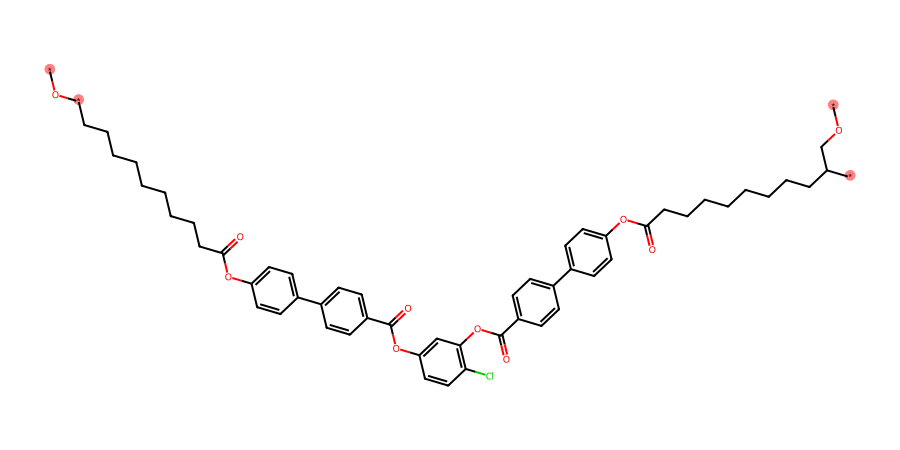

In [16]:
from rdkit.Chem import Draw

# Select the first flagged structure
example_index = connectivity_review.index[0]
example_mol = molecules.loc[example_index]

# Collect the indices of all dummy atoms
dummy_indices = [
    atom.GetIdx()
    for atom in example_mol.GetAtoms()
    if atom.GetAtomicNum() == 0
]

# Display the original identifier and full SMILES
print("Polymer ID:", train.loc[example_index, "id"])
print("SMILES:", train.loc[example_index, "SMILES"])

# Draw the represented structure and highlight its dummy atoms
display(
    Draw.MolToImage(
        example_mol,
        size=(900, 450),
        highlightAtoms=dummy_indices,
    )
)

| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `from rdkit.Chem import Draw` | Importiert das RDKit-Modul zum Zeichnen von Strukturen. | Imports the RDKit module for drawing structures. |
| `connectivity_review.index[0]` | Wählt den ursprünglichen Zeilenindex des ersten auffälligen Eintrags. | Selects the original row index of the first flagged entry. |
| `molecules.loc[example_index]` | Holt das zugehörige Molekülobjekt anhand dieses Index. | Retrieves the corresponding molecule object by its index. |
| `atom.GetIdx()` | Gibt den Index eines Atoms innerhalb dieses Moleküls zurück. | Returns an atom's index within this molecule. |
| `if atom.GetAtomicNum() == 0` | Nimmt nur Dummy-Atome in die Liste auf. | Includes only dummy atoms in the list. |
| `dummy_indices` | Liste der Atomindizes, die hervorgehoben werden sollen. | List of atom indices to highlight. |
| `train.loc[example_index, "SMILES"]` | Holt den vollständigen ursprünglichen SMILES-Text. | Retrieves the complete original SMILES string. |
| `Draw.MolToImage(...)` | Erstellt eine zweidimensionale Strukturzeichnung. | Creates a two-dimensional structure drawing. |
| `example_mol` | Das als erstes Argument übergebene Molekülobjekt. | The molecule object supplied as the first argument. |
| `size=(900, 450)` | Legt Bildbreite und Bildhöhe in Pixeln fest. | Sets the image width and height in pixels. |
| `highlightAtoms=dummy_indices` | Übergibt die Atomindizes für die Hervorhebung. | Supplies the atom indices to highlight. |

### Decision: unusual dummy-atom connectivity

Five structures contain a dummy atom with two directly bonded neighbours.
Visual inspection of the first case confirms this connectivity.

The intended representation remains unresolved. These entries are retained
and flagged for review. No automatic correction is applied.

In [17]:
# Generate canonical SMILES while preserving stereochemical information
def get_canonical_smiles(mol):
    if mol is None:
        return None

    return Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True,
    )


canonical_smiles = molecules.apply(get_canonical_smiles)

# Identify all members of repeated canonical-SMILES groups
canonical_duplicate_mask = (
    canonical_smiles.notna()
    & canonical_smiles.duplicated(keep=False)
)

print(
    "Rows belonging to repeated canonical-SMILES groups:",
    canonical_duplicate_mask.sum(),
)

# Display the original entries and their canonical representation
canonical_review = train.loc[
    canonical_duplicate_mask, ["id", "SMILES"]
].copy()

canonical_review["canonical_smiles"] = canonical_smiles.loc[
    canonical_duplicate_mask
]

display(canonical_review)

Rows belonging to repeated canonical-SMILES groups: 0


,id,SMILES,canonical_smiles


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `get_canonical_smiles` | Eigene Funktion zur Erzeugung einer kanonischen SMILES-Schreibweise. | Custom function for generating canonical SMILES. |
| `mol` | Parameter für ein RDKit-Molekülobjekt. | Parameter representing an RDKit molecule object. |
| `Chem.MolToSmiles(...)` | Wandelt ein Molekülobjekt wieder in einen SMILES-Text um. | Converts a molecule object back into a SMILES string. |
| `canonical=True` | Fordert die kanonische Schreibweise an. | Requests canonical output. |
| `isomericSmiles=True` | Behält vorhandene Stereochemie- und Isotopeninformationen in der Ausgabe bei. | Preserves available stereochemical and isotope information in the output. |
| `molecules.apply(...)` | Wendet die Funktion auf jedes eingelesene Molekül an. | Applies the function to each parsed molecule. |
| `canonical_smiles` | Series mit den erzeugten kanonischen SMILES. | Series containing the generated canonical SMILES. |
| `.notna()` | Schließt fehlende Ergebnisse aus der Duplikatmarkierung aus. | Excludes missing results from duplicate flagging. |
| `.duplicated(keep=False)` | Markiert alle Mitglieder einer wiederholten Gruppe, einschließlich des ersten. | Flags every member of a repeated group, including the first. |
| `&` | Verknüpft die beiden Bedingungen mit UND. | Combines the two conditions with AND. |
| `canonical_duplicate_mask.sum()` | Zählt die betroffenen Zeilen, nicht die Anzahl der Gruppen. | Counts affected rows, not the number of groups. |
| `.copy()` | Erstellt eine separate Untersuchungstabelle. | Creates a separate review table. |

### Findings: canonical-SMILES duplicate check

- No repeated canonical isomeric SMILES were found among the
  7,973 training structures using RDKit 2026.09.1.
- All generated canonical representations were distinct.
- This check does not establish uniqueness under alternative
  polymer repeat-unit representations.
- No observations were removed.

## 10. Descriptive statistics of the target properties

We summarise the available values for each prediction target.

The summary includes:
- non-missing value count;
- mean and standard deviation;
- minimum and maximum;
- 25th percentile, median and 75th percentile.

Missing target values are excluded separately for each property.
No values are imputed or removed.
Units still require confirmation from the dataset documentation.

Important: The statistics for Tg use its 511 available values, while those for FFV use its 7,030 values. We do not require the rows to be completely filled in for this purpose.

## 10. Deskriptive Statistik der Zielgrößen

Wir fassen die verfügbaren Werte für jede Zielgröße zusammen.

Die Zusammenfassung umfasst:
- Anzahl der vorhandenen (nicht fehlenden) Werte;
- Mittelwert und Standardabweichung;
- Minimum und Maximum;
- 25.-Perzentil, Median und 75.-Perzentil.

Fehlende Werte der Zielgrößen werden für jede Eigenschaft separat ausgeschlossen.
Es werden keine Werte imputiert oder entfernt.
Die Maßeinheiten müssen noch anhand der Dokumentation des Datensatzes bestätigt werden.

Wichtig: Die Statistik für Tg verwendet dessen 511 vorhandene Werte, die für FFV dessen 7.030 Werte. Wir verlangen dafür keine vollständig ausgefüllten Zeilen.

In [18]:
# Summarise each target using its available values
target_statistics = train[target_columns].describe().T

display(target_statistics)

,count,mean,std,min,25%,50%,75%,max
Tg,511.0,96.452314,111.228279,-148.029738,13.674509,74.040183,161.147595,472.250000
FFV,7030.0,0.367212,0.029609,0.226992,0.349549,0.364264,0.380790,0.777097
Tc,737.0,0.256334,0.089538,0.046500,0.186000,0.236000,0.330500,0.524000
Density,613.0,0.985484,0.146189,0.748691,0.890243,0.948193,1.062096,1.840999
Rg,614.0,16.419787,4.608640,9.728355,12.540328,15.052194,20.411067,34.672906


## 11. Target distributions

We plot a separate histogram for each target property.

Each histogram uses the available values for that target.
The full observed range is retained, including extreme values.
Axes are separate because the properties have different scales.

We inspect concentration, asymmetry, multiple peaks and extreme values.
Units remain unconfirmed and are therefore not added to the axes.

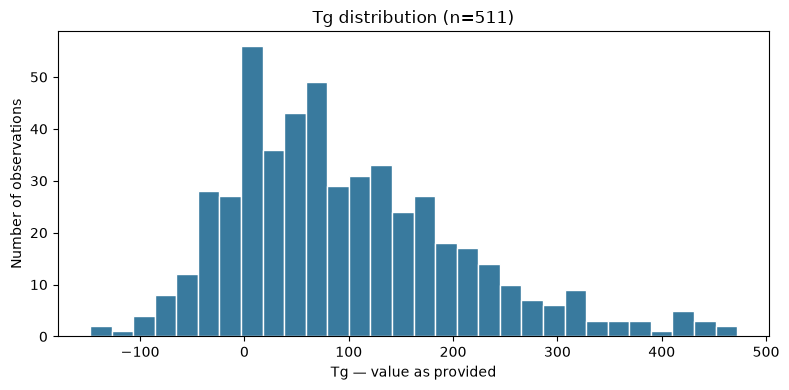

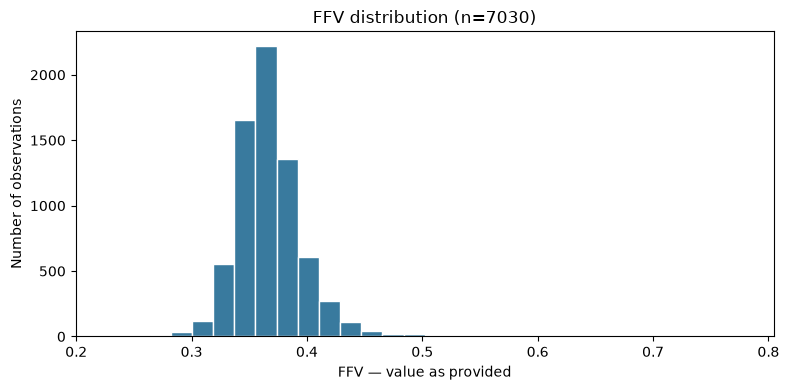

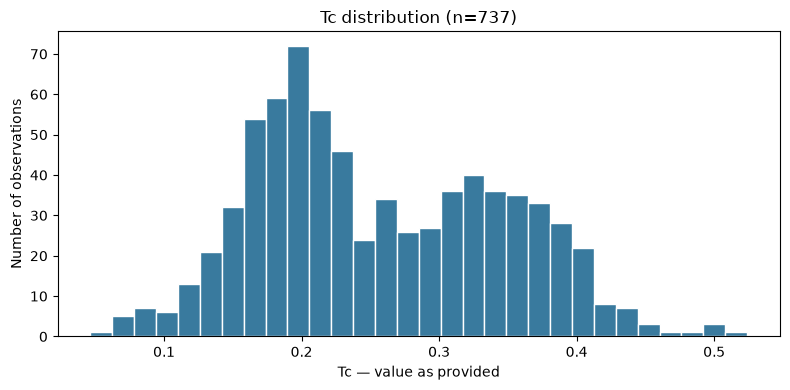

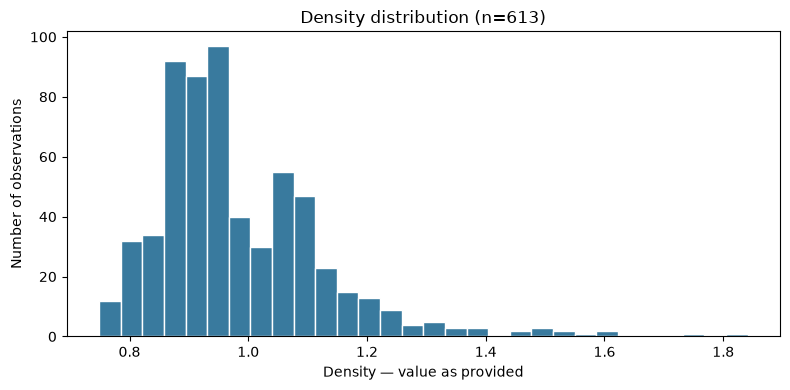

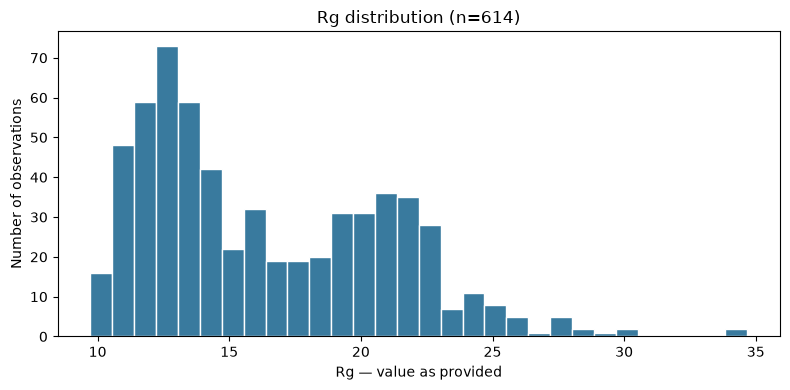

In [19]:
# Plot each target separately using all available values
for target in target_columns:
    values = train[target].dropna()

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.hist(
        values,
        bins=30,
        color="#397A9E",
        edgecolor="white",
    )

    ax.set_title(f"{target} distribution (n={len(values)})")
    ax.set_xlabel(f"{target} — value as provided")
    ax.set_ylabel("Number of observations")

    fig.tight_layout()
    plt.show()

| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `for target in target_columns:` | Durchläuft die fünf Zielspalten. | Iterates over the five target columns. |
| `target` | Variable für den aktuellen Spaltennamen. | Variable holding the current column name. |
| `train[target]` | Wählt die aktuelle Zielspalte als Series aus. | Selects the current target column as a Series. |
| `.dropna()` | Gibt die vorhandenen Werte zurück. Die ursprüngliche Tabelle bleibt unverändert. | Returns non-missing values without changing the original table. |
| `values` | Variable für die Werte der aktuellen Zielgröße. | Variable containing the current target's values. |
| `plt.subplots(...)` | Erstellt eine Figure und einen Zeichenbereich. | Creates a figure and an axes object. |
| `fig` | Das gesamte Diagrammobjekt. | The complete figure object. |
| `ax` | Der Zeichenbereich mit Achsen und Histogramm. | The plotting area containing axes and the histogram. |
| `figsize=(8, 4)` | Breite und Höhe der Figure in Zoll. | Figure width and height in inches. |
| `ax.hist(values, ...)` | Zeichnet das Histogramm der übergebenen Werte. | Draws a histogram of the supplied values. |
| `bins=30` | Teilt den Wertebereich in 30 gleich breite Intervalle. | Divides the value range into 30 equal-width intervals. |
| `color="#397A9E"` | Bestimmt die Balkenfarbe mit einem hexadezimalen Farbcode. | Sets the bar colour using a hexadecimal colour code. |
| `edgecolor="white"` | Zeichnet weiße Balkenränder. | Draws white bar edges. |
| `f"..."` | Formatierter String, der Ausdrücke in geschweiften Klammern einsetzt. | Formatted string that inserts expressions enclosed in braces. |
| `{target}` | Setzt den aktuellen Zielnamen in den Titel ein. | Inserts the current target name into the title. |
| `{len(values)}` | Setzt die Anzahl verwendeter Werte ein. | Inserts the number of observations used. |
| `ax.set_title(...)` | Setzt den Diagrammtitel. | Sets the chart title. |
| `ax.set_xlabel(...)` | Beschriftet die horizontale Achse. | Labels the horizontal axis. |
| `ax.set_ylabel(...)` | Beschriftet die vertikale Achse. | Labels the vertical axis. |
| `fig.tight_layout()` | Passt die Abstände innerhalb der Figure an. | Adjusts spacing within the figure. |
| `plt.show()` | Zeigt das Diagramm an. | Displays the chart. |

### Findings: initial target histograms

- FFV values are strongly concentrated around 0.36.
  Rare extreme values are difficult to see on the linear count scale.
- Tc shows a prominent peak around 0.20 and a broader secondary
  concentration around 0.32–0.37.
- Density is right-skewed, with relatively few high values.
- Rg shows possible multiple concentrations and a right-hand tail.
- Apparent peaks depend partly on histogram binning.
  They do not establish distinct polymer classes.
- Extreme values are retained pending further investigation.

In [20]:
# Select rows with available FFV values
ffv_review = train.loc[
    train["FFV"].notna(),
    ["id", "SMILES", "FFV"],
].copy()

# Inspect the upper and lower extremes
print("Ten highest FFV values:")
display(ffv_review.nlargest(10, "FFV"))

print("Ten lowest FFV values:")
display(ffv_review.nsmallest(10, "FFV"))

Ten highest FFV values:


,id,SMILES,FFV
6064,1645416728,*CCC1C[N+](C)(C)CC1*,0.777097
2966,806978622,*CC(*)O[N+](=O)[O-],0.774066
645,180321996,*CCCCCCCCCC[N+](*)(C)C,0.769315
2338,637669265,*CC(*)C(=O)NCCC[N+](C)(C)C,0.687057
2626,713393124,*CC(*)C(=O)N1CC[NH+](CC)CC1,0.650907
633,177272960,*c1ccc(*)[nH]1,0.563897
5385,1462748332,*c1ccc(-c2nc3ccc(-c4ccc5nc(*)c(-c6ccccc6)nc5c4...,0.532769
1374,370833911,*CCSSSS*,0.528203
3143,852184111,*c1cc(C)c(*)s1,0.516864
5032,1365848174,*c1ccc(-c2nc3cc4nc(-c5ccccc5)c(*)nc4cc3nc2-c2c...,0.513982


Ten lowest FFV values:


,id,SMILES,FFV
7705,2076949860,*CC(*)(CC(=O)O)C(=O)O,0.226992
4352,1173339618,*CC(*)C(N)=O,0.237637
5053,1370577687,*CC(*)C(=O)NCC(N)=O,0.245613
7536,2036966102,*C(*)O,0.245654
2198,595580163,*CC(*)(C)C(N)=O,0.256579
3036,822079361,*CC(*)C(=O)NCP(=O)(O)O,0.267393
4939,1337317565,*CC(*)(C)C(=O)O,0.271584
2159,584442637,*CC(OC)C(C(=O)O)C(*)C(=O)O,0.271790
4565,1231617285,*CC(*)NC=O,0.274937
4340,1169539258,*CC(*)(CC(=O)OC)C(=O)O,0.275583


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `train["FFV"].notna()` | Markiert Zeilen mit vorhandenem FFV-Wert. | Marks rows with an available FFV value. |
| `train.loc[..., ["id", "SMILES", "FFV"]]` | Wählt diese Zeilen und die drei angegebenen Spalten aus. | Selects these rows and the three specified columns. |
| `.copy()` | Erstellt eine separate Untersuchungstabelle. | Creates a separate review table. |
| `ffv_review` | Variable für die FFV-Untersuchungstabelle. | Variable containing the FFV review table. |
| `.nlargest(10, "FFV")` | Liefert die zehn Zeilen mit den höchsten FFV-Werten, absteigend sortiert. | Returns the ten rows with the highest FFV values, sorted in descending order. |
| `.nsmallest(10, "FFV")` | Liefert die zehn Zeilen mit den niedrigsten FFV-Werten, aufsteigend sortiert. | Returns the ten rows with the lowest FFV values, sorted in ascending order. |
| `10` | Argument für die gewünschte Zeilenanzahl; Parameter `n`. | Argument specifying the requested row count; parameter `n`. |
| `"FFV"` | Argument für die Spalte, nach der ausgewählt wird; Parameter `columns`. | Argument specifying the selection column; parameter `columns`. |

### Findings: FFV extreme values

- The three highest FFV values are approximately 0.769–0.777.
- Further high values occur around 0.687 and 0.651.
- There are noticeable gaps between some of the highest observations.
- The minimum FFV is approximately 0.227.
- The five highest SMILES entries contain positively charged nitrogen
  notation [N+]. This observation requires further investigation and
  does not establish a causal relationship.
- Extreme observations are retained. Their validity has not yet
  been established from source documentation.

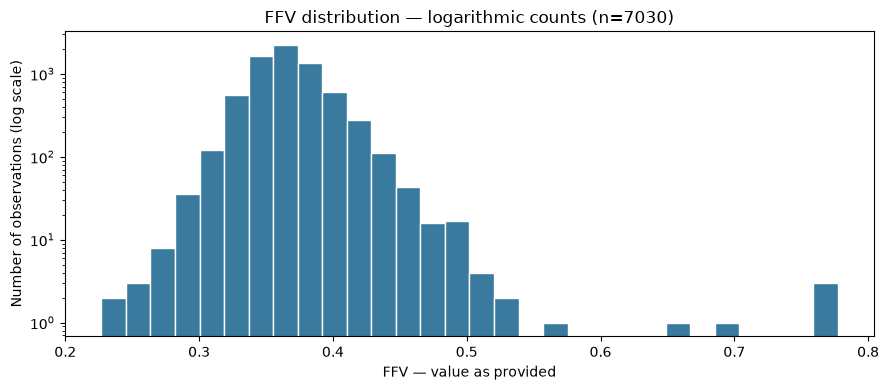

In [21]:
# Show rare FFV observations using a logarithmic count axis
ffv_values = train["FFV"].dropna()

fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    ffv_values,
    bins=30,
    log=True,
    color="#397A9E",
    edgecolor="white",
)

ax.set_title(f"FFV distribution — logarithmic counts (n={len(ffv_values)})")
ax.set_xlabel("FFV — value as provided")
ax.set_ylabel("Number of observations (log scale)")

fig.tight_layout()
plt.show()

### Findings: FFV histogram with logarithmic counts

- The logarithmic count axis makes sparsely populated intervals visible.
- Most FFV observations remain concentrated around 0.35–0.38.
- The upper tail contains a small number of widely separated values.
- The three highest observations around 0.77 fall into the same bin.
- The FFV values were not transformed, removed or corrected.
- This plot alone does not establish whether extreme values are valid.

Polymer ID: 1645416728
FFV: 0.77709707
SMILES: *CCC1C[N+](C)(C)CC1*


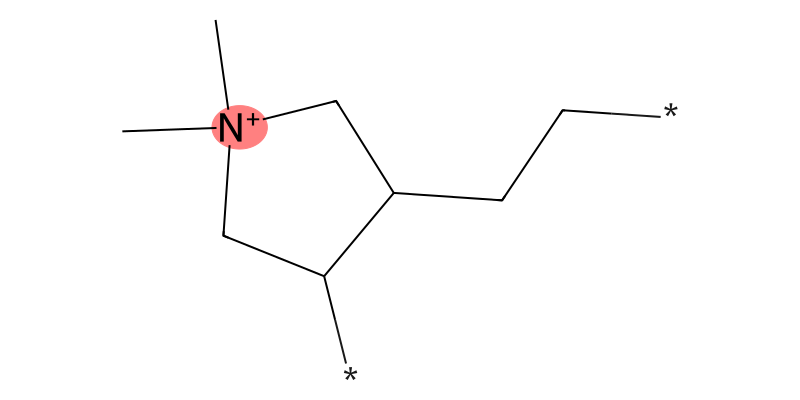

In [22]:
# Select the row with the highest available FFV value
highest_ffv_index = ffv_review["FFV"].idxmax()
highest_ffv_mol = molecules.loc[highest_ffv_index]

# Identify atoms with a non-zero formal charge
charged_atom_indices = [
    atom.GetIdx()
    for atom in highest_ffv_mol.GetAtoms()
    if atom.GetFormalCharge() != 0
]

print("Polymer ID:", train.loc[highest_ffv_index, "id"])
print("FFV:", train.loc[highest_ffv_index, "FFV"])
print("SMILES:", train.loc[highest_ffv_index, "SMILES"])

display(
    Draw.MolToImage(
        highest_ffv_mol,
        size=(800, 400),
        highlightAtoms=charged_atom_indices,
    )
)

### Visual inspection of the highest-FFV entry

- Entry ID 1645416728 has the highest observed FFV: 0.77709707.
- Its represented structure contains a nitrogen atom with formal charge +1.
- Two dummy atoms are present.
- The highlighted atom indicates formal charge, not an attachment point.
- This observation does not explain or validate the high FFV value.
- The entry is retained and flagged for further review.

### Formal charges in the ten highest-FFV entries

We inspect the number of formally charged atoms and the sum of
formal charges in each represented structure.

A zero total formal charge does not imply that every atom is uncharged.
This analysis describes the stored molecular graphs and does not
establish why their FFV values are high.

No structures or target values are modified.

In [23]:
# Count atoms with a non-zero formal charge
def count_charged_atoms(mol):
    if mol is None:
        return None

    return sum(
        atom.GetFormalCharge() != 0
        for atom in mol.GetAtoms()
    )


# Sum the formal charges of all atoms
def sum_formal_charges(mol):
    if mol is None:
        return None

    return sum(
        atom.GetFormalCharge()
        for atom in mol.GetAtoms()
    )


# Select the ten highest-FFV entries and their molecules
top_ffv_charge_review = ffv_review.nlargest(10, "FFV").copy()
top_ffv_molecules = molecules.loc[top_ffv_charge_review.index]

# Add charge information, aligned by the original row index
top_ffv_charge_review["charged_atom_count"] = (
    top_ffv_molecules.apply(count_charged_atoms)
)

top_ffv_charge_review["total_formal_charge"] = (
    top_ffv_molecules.apply(sum_formal_charges)
)

display(
    top_ffv_charge_review[
        ["id", "FFV", "charged_atom_count", "total_formal_charge"]
    ]
)

,id,FFV,charged_atom_count,total_formal_charge
6064,1645416728,0.777097,1,1
2966,806978622,0.774066,2,0
645,180321996,0.769315,1,1
2338,637669265,0.687057,1,1
2626,713393124,0.650907,1,1
633,177272960,0.563897,0,0
5385,1462748332,0.532769,0,0
1374,370833911,0.528203,0,0
3143,852184111,0.516864,0,0
5032,1365848174,0.513982,0,0


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `def` | Definiert eine eigene Funktion. | Defines a custom function. |
| `mol` | Parameter für ein einzelnes Molekülobjekt. | Parameter representing one molecule object. |
| `if mol is None:` | Prüft, ob das Molekülobjekt fehlt. | Checks whether the molecule object is missing. |
| `return None` | Beendet die Funktion ohne berechneten Wert. | Exits the function without a calculated value. |
| `mol.GetAtoms()` | Liefert die Atome zum Durchlaufen. | Provides the atoms for iteration. |
| `atom.GetFormalCharge()` | Gibt die formale Ladung des aktuellen Atoms zurück. | Returns the current atom's formal charge. |
| `!= 0` | Prüft, ob die Ladung ungleich null ist. | Checks whether the charge is non-zero. |
| `sum(...)` | Addiert Ladungen oder zählt wahre Bedingungen, abhängig vom übergebenen Ausdruck. | Adds charges or counts true conditions, depending on the supplied expression. |
| `.nlargest(10, "FFV")` | Wählt die zehn höchsten FFV-Einträge aus. | Selects the ten highest-FFV entries. |
| `.copy()` | Erstellt eine separate Untersuchungstabelle. | Creates a separate review table. |
| `top_ffv_charge_review.index` | Enthält die ursprünglichen Zeilenindizes der ausgewählten Einträge. | Contains the original row indices of the selected entries. |
| `molecules.loc[...]` | Wählt die zugehörigen Molekülobjekte aus. | Selects the corresponding molecule objects. |
| `.apply(count_charged_atoms)` | Zählt geladene Atome für jedes ausgewählte Molekül. | Counts charged atoms for each selected molecule. |
| `.apply(sum_formal_charges)` | Berechnet die Ladungssumme für jedes ausgewählte Molekül. | Calculates the formal-charge sum for each selected molecule. |

### Findings: formal charges in the highest-FFV entries

- All five highest-FFV entries contain formally charged atoms.
- Four have a total formal charge of +1.
- One entry, ID 806978622, contains two charged atoms but has
  a total formal charge of zero.
- Entries ranked 6–10 contain no formally charged atoms.
- These findings describe the selected extremes only.
  They do not establish causation or invalidate the target values.
- No observations were removed.

In [24]:
# Count formally charged atoms in all parsed structures. (Zähle formal geladene Atome in allen analysierten Strukturen)
charged_atom_counts = molecules.apply(count_charged_atoms)

# Create a separate table for the FFV group comparison. (Erstelle eine separate Tabelle für den FFV-Gruppenvergleich.)
ffv_charge_comparison = ffv_review.copy()

ffv_charge_comparison["charged_atom_count"] = (
    charged_atom_counts.loc[ffv_charge_comparison.index]
)

ffv_charge_comparison["has_charged_atoms"] = (
    ffv_charge_comparison["charged_atom_count"].gt(0)
)

# Summarise FFV separately for both groups
ffv_charge_summary = (
    ffv_charge_comparison
    .groupby("has_charged_atoms")["FFV"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(ffv_charge_summary)

,count,mean,median,min,max
has_charged_atoms,,,,,
False,6841,0.366896,0.364270,0.226992,0.563897
True,189,0.378636,0.363822,0.333269,0.777097


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `.apply(count_charged_atoms)` | Wendet unsere vorhandene Zählfunktion auf jedes Molekül an. | Applies our existing counting function to each molecule. |
| `.loc[ffv_charge_comparison.index]` | Wählt die Anzahlen für die passenden FFV-Zeilen aus. | Selects counts for the corresponding FFV rows. |
| `.gt(0)` | Prüft, ob die Anzahl größer als null ist. | Checks whether the count is greater than zero. |
| `"has_charged_atoms"` | Neue Spalte: `True` bei mindestens einem geladenen Atom, sonst `False`. | New column: `True` for at least one charged atom, otherwise `False`. |
| `.groupby("has_charged_atoms")` | Gruppiert die Zeilen nach dieser Kennzeichnung. | Groups rows by this indicator. |
| `["FFV"]` | Wählt die zu untersuchenden Werte innerhalb der Gruppen aus. | Selects the values to examine within each group. |
| `.agg([...])` | Berechnet mehrere angegebene Statistiken je Gruppe. | Calculates several specified statistics for each group. |
| `"count"` | Anzahl vorhandener FFV-Werte je Gruppe. | Number of available FFV values per group. |
| `"mean"` / `"median"` | Mittelwert und Median je Gruppe. | Mean and median per group. |
| `"min"` / `"max"` | Kleinster und größter Wert je Gruppe. | Minimum and maximum value per group. |

### Findings: FFV comparison by presence of formally charged atoms

- Of the 7,030 FFV-labelled structures, 189 (approximately 2.69%)
  contain at least one formally charged atom.
- Their mean FFV is higher: 0.378636 versus 0.366896.
- The medians are nearly identical: 0.363822 versus 0.364270.
- The difference between means is consistent with the influence
  of the high upper-tail values identified earlier.
- The groups differ substantially in size.
- This descriptive comparison does not establish a causal effect
  or justify removing charged structures.
- All observations are retained.

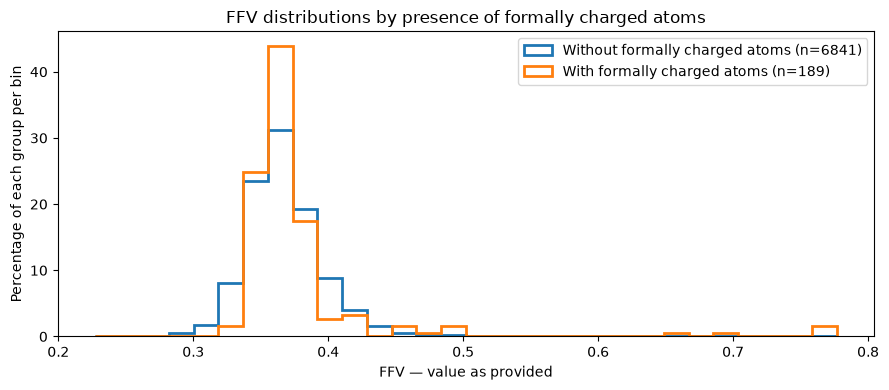

In [25]:
# Use identical bin boundaries for both groups
bin_edges = np.linspace(
    ffv_charge_comparison["FFV"].min(),
    ffv_charge_comparison["FFV"].max(),
    31,
)

fig, ax = plt.subplots(figsize=(9, 4))

for has_charge, group in ffv_charge_comparison.groupby("has_charged_atoms"):
    values = group["FFV"]

    # Each group's observations sum to 100 percent
    weights = np.full(len(values), 100 / len(values))

    label = (
        "With formally charged atoms"
        if has_charge
        else "Without formally charged atoms"
    )

    ax.hist(
        values,
        bins=bin_edges,
        weights=weights,
        histtype="step",
        linewidth=2,
        label=f"{label} (n={len(values)})",
    )

ax.set_title("FFV distributions by presence of formally charged atoms")
ax.set_xlabel("FFV — value as provided")
ax.set_ylabel("Percentage of each group per bin")
ax.legend()

fig.tight_layout()
plt.show()

| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `np.linspace(minimum, maximum, 31)` | Erstellt 31 gleichmäßig verteilte Grenzen für 30 Intervalle. | Creates 31 equally spaced boundaries for 30 bins. |
| `for has_charge, group in ...` | Liefert je Durchlauf den Gruppenschlüssel und die zugehörige Tabelle. | Provides the group key and its table in each iteration. |
| `has_charge` | Gruppenschlüssel: `True` oder `False`. | Group key: `True` or `False`. |
| `group` | Tabelle der aktuellen Gruppe. | Table containing the current group. |
| `np.full(len(values), 100 / len(values))` | Erstellt für jede Beobachtung dasselbe Prozentgewicht. | Creates the same percentage weight for every observation. |
| `weights=weights` | Addiert im Histogramm diese Gewichte statt bloßer Anzahlen. | Sums these weights instead of raw counts in the histogram. |
| `histtype="step"` | Zeichnet die Histogramme als Umrisslinien, damit beide sichtbar bleiben. | Draws histogram outlines so both remain visible. |
| `linewidth=2` | Legt die Linienstärke fest. | Sets the line width. |
| `label=...` | Beschriftung der jeweiligen Gruppe für die Legende. | Group label used in the legend. |
| `ax.legend()` | Zeigt die Legende an. | Displays the legend. |

## 12. Target quantiles and tail inspection

We calculate additional quantiles for each target to inspect its tails.

The 1st and 99th percentiles help distinguish the central distribution
from sparsely populated extremes. They are descriptive markers,
not automatic thresholds for removing observations.

Missing values are excluded separately for each target.
No observations are modified or removed.

In [26]:
# Inspect the centre and tails of each target distribution
quantile_levels = [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]

target_quantiles = (
    train[target_columns]
    .quantile(quantile_levels)
    .T
)

display(target_quantiles)

,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
Tg,-148.029738,-90.165068,-49.041020,13.674509,74.040183,161.147595,311.948697,423.228584,472.250000
FFV,0.226992,0.306384,0.327622,0.349549,0.364264,0.380790,0.416925,0.451024,0.777097
Tc,0.046500,0.084360,0.131700,0.186000,0.236000,0.330500,0.403350,0.450243,0.524000
Density,0.748691,0.772621,0.806181,0.890243,0.948193,1.062096,1.234910,1.515912,1.840999
Rg,9.728355,10.064432,10.870906,12.540328,15.052194,20.411067,24.349463,28.234264,34.672906


### Findings: target quantiles

- For FFV, the 99th percentile is approximately 0.451,
  while the maximum is approximately 0.777.
- This supports the earlier observation of a sparse, extended upper tail.
- Density and Rg also have maxima above their 99th percentiles.
- Quantiles describe relative positions within each target distribution.
  They do not establish physical plausibility.
- The 1st and 99th percentiles are not used as deletion thresholds.
- All observations are retained.

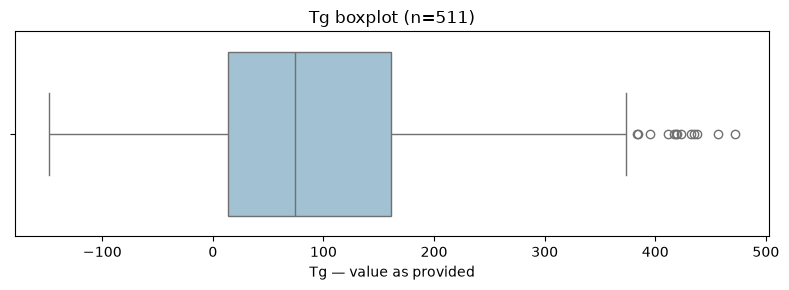

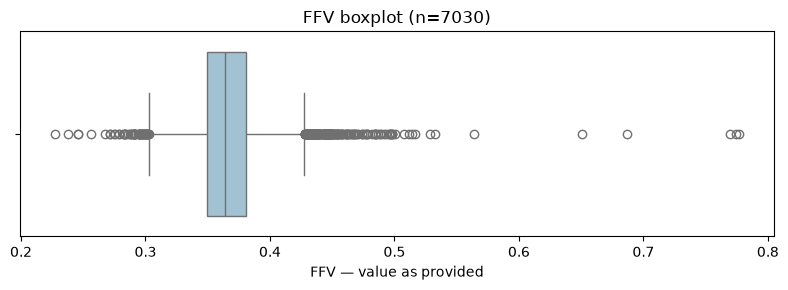

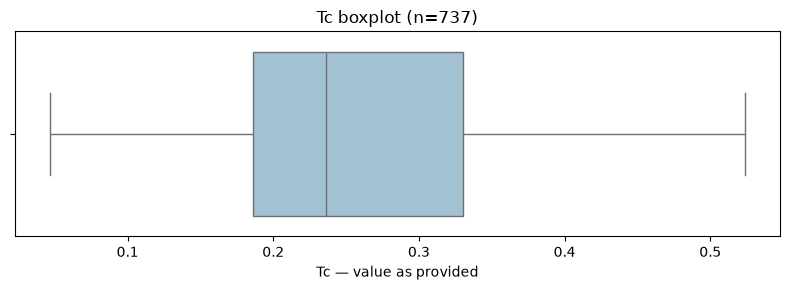

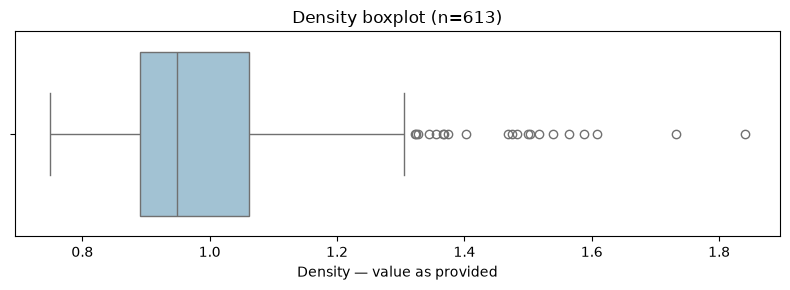

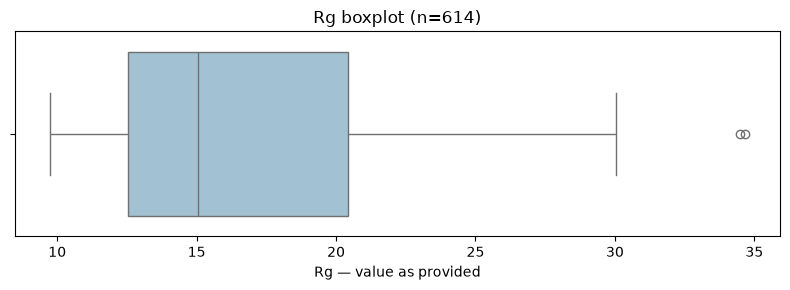

In [27]:
# Display each target using the standard 1.5-IQR boxplot rule
for target in target_columns:
    values = train[target].dropna()

    fig, ax = plt.subplots(figsize=(8, 3))

    sns.boxplot(
        x=values,
        whis=1.5,
        color="#9AC4DB",
        ax=ax,
    )

    ax.set_title(f"{target} boxplot (n={len(values)})")
    ax.set_xlabel(f"{target} — value as provided")

    fig.tight_layout()
    plt.show()

### Findings: target boxplots

- The 1.5-IQR rule flags upper-tail observations for Tg, Density and Rg.
- FFV has flagged observations in both tails.
- Tc has no observations outside the boxplot fences.
- The rule identifies statistical extremes, not confirmed data errors.
- Overlapping plot markers do not reliably show the number of
  flagged observations.
- All observations are retained.

## 13. IQR-based target review

We calculate the lower and upper fences using the 1.5 × IQR rule
and count the observations outside these fences for each target.

These are statistical review thresholds, not physical validity limits.
Missing values are excluded separately for each target.
No observations are modified or removed.

In [28]:
# Collect IQR-based review statistics for each target
iqr_rows = []

for target in target_columns:
    values = train[target].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    below_count = values.lt(lower_fence).sum()
    above_count = values.gt(upper_fence).sum()
    flagged_count = below_count + above_count

    iqr_rows.append({
        "target": target,
        "available_count": len(values),
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "below_count": below_count,
        "above_count": above_count,
        "flagged_count": flagged_count,
        "flagged_percent": flagged_count / len(values) * 100,
    })

iqr_summary = pd.DataFrame(iqr_rows).set_index("target")

display(iqr_summary.round(4))

,available_count,lower_fence,upper_fence,below_count,above_count,flagged_count,flagged_percent
target,,,,,,,
Tg,511,-207.5351,382.3572,0,13,13,2.5440
FFV,7030,0.3027,0.4277,57,212,269,3.8265
Tc,737,-0.0308,0.5472,0,0,0,0.0000
Density,613,0.6325,1.3199,0,21,21,3.4258
Rg,614,0.7342,32.2172,0,2,2,0.3257


| Bestandteil | Bedeutung | Meaning (English) |
|---|---|---|
| `iqr_rows = []` | Erstellt eine leere Liste für die Ergebnisse. | Creates an empty list for the results. |
| `.quantile(0.25)` | Berechnet das erste Quartil. | Calculates the first quartile. |
| `.quantile(0.75)` | Berechnet das dritte Quartil. | Calculates the third quartile. |
| `iqr = q3 - q1` | Berechnet den Interquartilsabstand. | Calculates the interquartile range. |
| `lower_fence` / `upper_fence` | Berechnete statistische Untersuchungsgrenzen. | Calculated statistical review thresholds. |
| `.lt(lower_fence)` | Prüft auf Werte strikt unterhalb der unteren Grenze. | Checks for values strictly below the lower threshold. |
| `.gt(upper_fence)` | Prüft auf Werte strikt oberhalb der oberen Grenze. | Checks for values strictly above the upper threshold. |
| `flagged_count` | Summe der markierten Werte beider Seiten. | Total number of flagged values in both tails. |
| `.append({...})` | Fügt ein Dictionary mit den Ergebnissen einer Zielgröße zur Liste hinzu. | Appends a dictionary containing one target's results to the list. |
| `.set_index("target")` | Verwendet die Zielnamen als Zeilenindex. | Uses target names as the row index. |
| `.round(4)` | Rundet die angezeigte Ergebniskopie auf vier Nachkommastellen. | Rounds the displayed result copy to four decimal places. |

### Findings: IQR-based target review

The 1.5 × IQR rule was applied separately to the non-missing
values of each target.

| Target | Available values | Below lower fence | Above upper fence | Total flagged | Flagged (%) |
|---|---:|---:|---:|---:|---:|
| Tg | 511 | 0 | 13 | 13 | 2.54 |
| FFV | 7,030 | 57 | 212 | 269 | 3.83 |
| Tc | 737 | 0 | 0 | 0 | 0.00 |
| Density | 613 | 0 | 21 | 21 | 3.43 |
| Rg | 614 | 0 | 2 | 2 | 0.33 |

FFV has the highest proportion of flagged values.
For Tg, Density, and Rg, all flagged values are above
the upper fence. No Tc values fall outside the IQR fences.

These fences are statistical review thresholds, not physical
validity limits. Flagged values are not automatically errors,
and values within the fences are not automatically valid.

All observations are retained at this stage.
Percentages are calculated using the available values
of each target.

## 14. Relationships between target properties

We examine pairwise relationships between the target properties
using Spearman correlation.

Each correlation is interpreted alongside the number of jointly
available observations. Different target pairs may use different
subsets of polymers.

Correlation does not establish causation.

In [29]:
# Select the target columns
target_data = train[target_columns]

# Count jointly available observations for each target pair
target_available = target_data.notna().astype("int64")
pair_counts = target_available.T.dot(target_available)

# Calculate pairwise Spearman correlations
spearman_corr = target_data.corr(method="spearman")

# Display counts and correlations
print("Jointly available observations:")
display(pair_counts)

print("Spearman correlation:")
display(spearman_corr.round(3))

Jointly available observations:


,Tg,FFV,Tc,Density,Rg
Tg,511,1,32,24,24
FFV,1,7030,300,270,270
Tc,32,300,737,531,535
Density,24,270,531,613,610
Rg,24,270,535,610,614


Spearman correlation:


,Tg,FFV,Tc,Density,Rg
Tg,1.000,NaN,-0.218,0.418,0.099
FFV,NaN,1.000,0.227,-0.502,-0.011
Tc,-0.218,0.227,1.000,-0.454,0.505
Density,0.418,-0.502,-0.454,1.000,0.163
Rg,0.099,-0.011,0.505,0.163,1.000


### Findings: pairwise target correlations

The strongest observed Spearman correlations are:

- FFV–Density: −0.502, based on 270 paired observations.
- Tc–Rg: +0.505, based on 535 paired observations.
- Tc–Density: −0.454, based on 531 paired observations.

FFV–Rg shows almost no monotonic association
(−0.011; 270 paired observations).

Correlations involving Tg require particular caution because
only 24–32 paired observations are available for the
calculable relationships. Tg–FFV cannot be calculated
because only one paired observation is available.

Each correlation describes the subset where both targets
are observed. Different target pairs may use different subsets.

These exploratory associations do not establish causation.
Scatter plots will be used to inspect the patterns.

### 14.1 Scatter plot: FFV and Density

We visualize the relationship between FFV and Density using
observations where both target values are available.

Each point represents one training row.
The scatter plot helps inspect the overall pattern,
possible groups, and unusual observations.

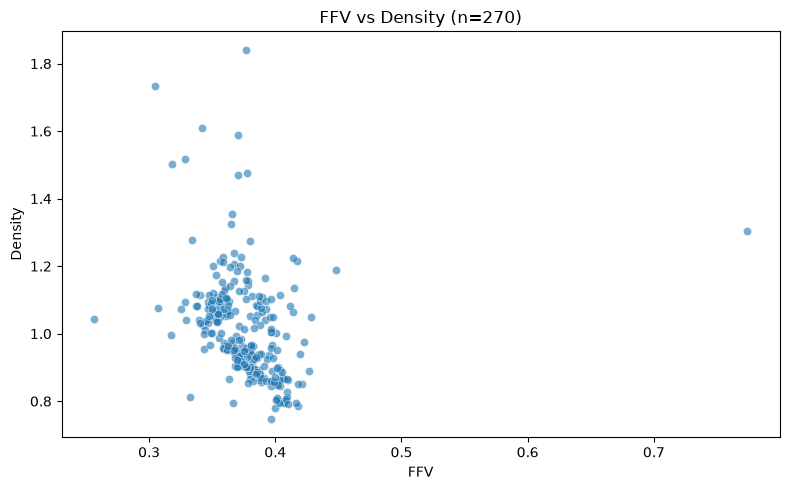

In [30]:
# Select paired observations without changing the training dataset
ffv_density_pairs = train[["FFV", "Density"]].dropna()

# Create the figure and axes
fig, ax = plt.subplots(figsize=(8, 5))

# Plot one point for each paired observation
sns.scatterplot(
    data=ffv_density_pairs,
    x="FFV",
    y="Density",
    alpha=0.6,
    s=35,
    ax=ax,
)

# Add a title and axis labels
ax.set_title(
    f"FFV vs Density (n={len(ffv_density_pairs)})"
)
ax.set_xlabel("FFV")
ax.set_ylabel("Density")

# Adjust spacing and display the figure
fig.tight_layout()
plt.show()

#### Findings: FFV and Density

The scatter plot shows a downward tendency in the main
point cloud, consistent with the Spearman correlation
of −0.502 across 270 paired observations.

Most paired observations are concentrated approximately
between FFV 0.33–0.42 and Density 0.8–1.2.

Considerable scatter remains: similar FFV values can occur
with different Density values.

Several observations lie away from the main point cloud,
including one at approximately FFV 0.77 and Density 1.30.
These observations are retained.

The findings describe the subset with both targets available
and do not establish causation.

### 14.2 Scatter plot: Tc and Rg

We visualize the relationship between Tc and Rg using
observations where both target values are available.

Each point represents one training row.
We inspect the positive association suggested by the
Spearman correlation of +0.505 across 535 paired observations.

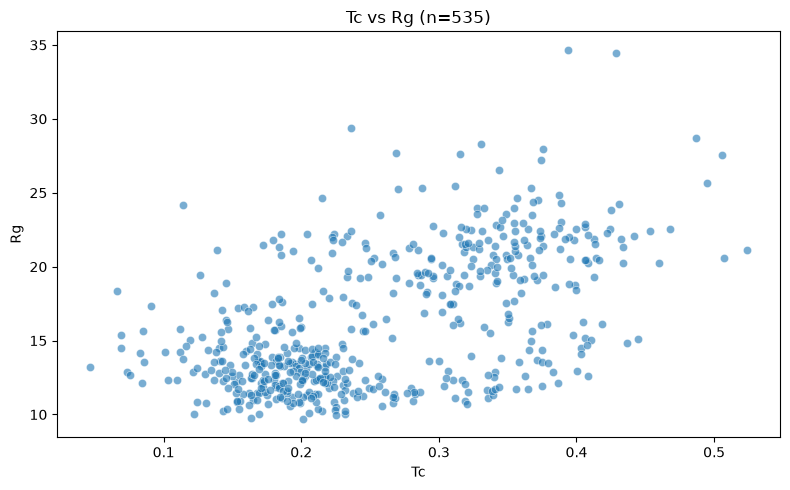

In [31]:
# Select rows where both targets are available
tc_rg_pairs = train[["Tc", "Rg"]].dropna()

# Create the figure and axes
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the paired observations
sns.scatterplot(
    data=tc_rg_pairs,
    x="Tc",
    y="Rg",
    alpha=0.6,
    s=35,
    ax=ax,
)

# Add a title and axis labels
ax.set_title(f"Tc vs Rg (n={len(tc_rg_pairs)})")
ax.set_xlabel("Tc")
ax.set_ylabel("Rg")

# Adjust spacing and display the figure
fig.tight_layout()
plt.show()

#### Findings: Tc and Rg

The scatter plot shows an overall positive association,
consistent with the Spearman correlation of +0.505
across 535 paired observations.

Two visually dense regions occur approximately around:
- Tc 0.14–0.23 and Rg 10–15.
- Tc 0.30–0.42 and Rg 18–24.

Considerable scatter remains, including low Rg values
at higher Tc values. A single straight-line description
would therefore capture only part of the visible pattern.

The dense regions do not establish distinct polymer classes
or data sources. Two observations have Rg values around 34–35.
All observations are retained.

These findings describe the subset with both targets available
and do not establish causation.

### 14.3 Scatter plot: Tc and Density

We visualize the relationship between Tc and Density using
observations where both target values are available.

Each point represents one training row.
We inspect the negative association suggested by the
Spearman correlation of −0.454 across 531 paired observations.

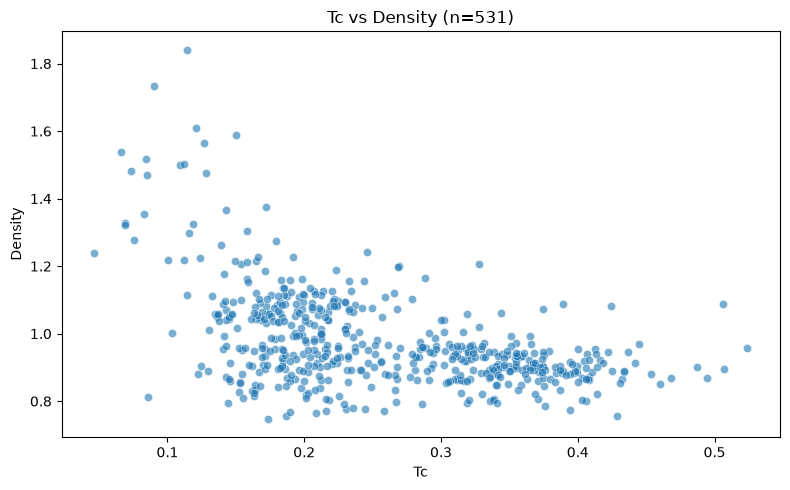

In [32]:
# Select rows where both targets are available
tc_density_pairs = train[["Tc", "Density"]].dropna()

# Create the figure and axes
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the paired observations
sns.scatterplot(
    data=tc_density_pairs,
    x="Tc",
    y="Density",
    alpha=0.6,
    s=35,
    ax=ax,
)

# Add a title and axis labels
ax.set_title(f"Tc vs Density (n={len(tc_density_pairs)})")
ax.set_xlabel("Tc")
ax.set_ylabel("Density")

# Adjust spacing and display the figure
fig.tight_layout()
plt.show()

#### Findings: Tc and Density

The scatter plot shows an overall negative association,
consistent with the Spearman correlation of −0.454
across 531 paired observations.

Many observations around Tc 0.15–0.23 have Density values
approximately between 0.8 and 1.15.

Around Tc 0.30–0.42, many Density values are concentrated
approximately between 0.85 and 0.97.

Several high Density values occur at relatively low Tc.
Considerable scatter remains, so Tc alone does not
uniquely determine Density.

All observations are retained. These findings describe
the subset with both targets available and do not
establish causation.

### 14.4 Summary and implications for modeling

Three selected target relationships were inspected:

| Target pair | Paired observations | Spearman correlation |
|---|---:|---:|
| FFV–Density | 270 | −0.502 |
| Tc–Rg | 535 | +0.505 |
| Tc–Density | 531 | −0.454 |

The scatter plots show broad trends alongside substantial
scatter and visually dense regions.

Correlations involving Tg have limited paired observations.
Tg–FFV cannot be calculated because only one pair is available.

These findings do not justify removing observations,
filling missing targets, or assuming causal relationships.

For the initial models, molecular features will be used
to predict each target separately. Other target properties
will not be assumed to be available at prediction time.

## 15. Data sources, target units and supplementary datasets

We review the supplementary datasets before considering
their use in model development.

The review covers their structure, available labels,
provenance, units, and overlapping polymer structures.

No supplementary data are merged at this stage.

### 15.1 Structure and completeness of supplementary datasets

For each supplementary dataset, we inspect the first rows,
column data types, and non-missing value counts.

In [33]:
# List the supplementary dataset keys
supplement_files = [
    "raw/train_supplement/dataset1.csv",
    "raw/train_supplement/dataset2.csv",
    "raw/train_supplement/dataset3.csv",
    "raw/train_supplement/dataset4.csv",
]

# Inspect each supplementary dataset
for file_name in supplement_files:
    supplement = datasets[file_name]

    print(f"\nFile: {file_name}")
    print(f"Shape: {supplement.shape}")

    display(supplement.head(3))
    supplement.info()


File: raw/train_supplement/dataset1.csv
Shape: (874, 2)


,SMILES,TC_mean
0,*/C(=C(\c1ccccc1)c1ccc(*)cc1)c1ccccc1,0.3380
1,*/C(F)=C(\F)C(F)(C(*)(F)F)C(F)(F)F,0.1020
2,*/C=C(/*)C#CCCCCCCCCCCCCCCCCCCCCC(=O)O,0.4105


<class 'pandas.DataFrame'>
RangeIndex: 874 entries, 0 to 873
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SMILES   874 non-null    str    
 1   TC_mean  874 non-null    float64
dtypes: float64(1), str(1)
memory usage: 13.8 KB

File: raw/train_supplement/dataset2.csv
Shape: (7208, 1)


,SMILES
0,*/C(=C(/*)c1ccc(C(C)(C)C)cc1)c1ccccc1
1,*/C(=C(/*)c1ccc(CCCC)cc1)c1ccccc1
2,*/C(=C(/*)c1ccc(Oc2ccccc2)cc1)c1ccccc1


<class 'pandas.DataFrame'>
RangeIndex: 7208 entries, 0 to 7207
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   SMILES  7208 non-null   str  
dtypes: str(1)
memory usage: 56.4 KB

File: raw/train_supplement/dataset3.csv
Shape: (46, 2)


,SMILES,Tg
0,*=Nc1ccc(N=C(C)Nc2ccc(-c3ccc(NC(=*)C)c(C(=O)O)...,89.380459
1,*C(=O)OC(=O)COc1ccc(OCC(=O)OC(=O)c2ccc(*)nc2)cc1,155.970957
2,*C(=O)c1ccc(C(=O)c2ccc(C=C3CCC(=Cc4ccc(*)cc4)C...,192.209684


<class 'pandas.DataFrame'>
RangeIndex: 46 entries, 0 to 45
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SMILES  46 non-null     str    
 1   Tg      46 non-null     float64
dtypes: float64(1), str(1)
memory usage: 868.0 bytes

File: raw/train_supplement/dataset4.csv
Shape: (862, 2)


,SMILES,FFV
0,*C(=O)NNC(=O)c1ccc([Si](c2ccccc2)(c2ccccc2)c2c...,0.372725
1,*C(=O)NNC(=O)c1ccc([Si](c2ccccc2)(c2ccccc2)c2c...,0.365478
2,*C(=O)Nc1cc(NC(=O)c2ccc3[nH]c(-c4cc(-c5nc6cc(*...,0.376377


<class 'pandas.DataFrame'>
RangeIndex: 862 entries, 0 to 861
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SMILES  862 non-null    str    
 1   FFV     862 non-null    float64
dtypes: float64(1), str(1)
memory usage: 13.6 KB


#### Findings: supplementary dataset structure

| Dataset | Rows | Columns | Missing values reported by info() |
|---|---:|---|---:|
| dataset1.csv | 874 | SMILES, TC_mean | 0 |
| dataset2.csv | 7,208 | SMILES | 0 |
| dataset3.csv | 46 | SMILES, Tg | 0 |
| dataset4.csv | 862 | SMILES, FFV | 0 |

Datasets 1, 3, and 4 contain potential supplementary labels.
Dataset 2 contains structures only and is set aside for
the initial supervised baseline.

Non-null counts do not establish valid SMILES, unique
structures, or compatible target definitions.

Before merging, we must verify provenance, units,
the meaning of TC_mean, and overlapping structures.

No supplementary observations have been added to train.

### 15.2 Data provenance and target units

The competition describes the five targets as properties
derived from molecular dynamics simulations.

| Target | Unit |
|---|---|
| Tg | °C |
| FFV | Dimensionless fraction |
| Tc | W/(m·K) |
| Density | g/cm³ |
| Rg | Å |

Datasets 1, 3, and 4 contain older host simulation results.
Dataset 1 is described as supplementary Tc data, but the
aggregation behind TC_mean is not specified on the data page.

Decision: retain the original supplementary column names.
Use the main training dataset for the initial baseline.
Supplementary data remain separate pending compatibility
and overlap checks.

Source:
https://www.kaggle.com/competitions/neurips-open-polymer-prediction-2025/data

### 15.3 Exact SMILES duplicates and training-set overlap

We first compare SMILES strings exactly as stored.

For each supplementary dataset, we count unique non-missing
SMILES, repeated occurrences beyond the first, and matches
with the main training dataset.

Exact string matching does not detect alternative SMILES
representations of the same molecular structure.

No observations are merged or removed.

In [34]:
# Collect unique non-missing training SMILES
train_smiles_set = set(train["SMILES"].dropna())

# Collect review results
overlap_rows = []

for file_name in supplement_files:
    supplement = datasets[file_name]
    supplement_smiles = supplement["SMILES"].dropna()

    matches_train = supplement_smiles.isin(train_smiles_set)

    overlap_rows.append({
        "file": file_name,
        "rows": len(supplement),
        "missing_smiles": supplement["SMILES"].isna().sum(),
        "unique_smiles": supplement_smiles.nunique(),
        "repeated_occurrences": supplement_smiles.duplicated().sum(),
        "matching_rows": matches_train.sum(),
        "matching_unique_smiles": (
            supplement_smiles[matches_train].nunique()
        ),
    })

# Display the exact-match review
exact_overlap_summary = pd.DataFrame(overlap_rows)
display(exact_overlap_summary)

,file,rows,missing_smiles,unique_smiles,repeated_occurrences,matching_rows,matching_unique_smiles
0,raw/train_supplement/dataset1.csv,874,0,867,7,744,737
1,raw/train_supplement/dataset2.csv,7208,0,7174,34,5212,5191
2,raw/train_supplement/dataset3.csv,46,0,46,0,0,0
3,raw/train_supplement/dataset4.csv,862,0,862,0,0,0


#### Findings: exact SMILES duplicates and overlap

| Dataset | Rows | Unique SMILES | Repeated occurrences | Matching rows in train | Unique matching SMILES |
|---|---:|---:|---:|---:|---:|
| dataset1.csv | 874 | 867 | 7 | 744 | 737 |
| dataset2.csv | 7,208 | 7,174 | 34 | 5,212 | 5,191 |
| dataset3.csv | 46 | 46 | 0 | 0 | 0 |
| dataset4.csv | 862 | 862 | 0 | 0 | 0 |

No missing SMILES values were detected.

Dataset 1 contains 130 unique SMILES strings not found
in train by exact matching. Its overlapping structures
require label comparison before any integration.

Datasets 3 and 4 have no exact SMILES matches with train.
This does not yet establish that their molecular
structures are absent from train.

Canonical SMILES comparison is the next check.
No observations have been merged or removed.

### 15.3.1 Canonical SMILES overlap

We use RDKit canonical isomeric SMILES to compare the
represented molecular structures across datasets.

Parsing failures are counted and excluded from matching.
Stereochemistry is retained in the canonical representation.

This comparison does not establish complete polymer
equivalence across different repeat-unit representations.

No observations are merged or removed.

In [35]:
# Define a consistent canonicalization function
def canonicalize_smiles(smiles_text):
    if pd.isna(smiles_text):
        return None

    mol = Chem.MolFromSmiles(smiles_text)

    if mol is None:
        return None

    return Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True,
    )


# Canonicalize training structures
train_canonical = train["SMILES"].apply(canonicalize_smiles)
train_canonical_set = set(train_canonical.dropna())

# Store supplementary canonical strings and review results
supplement_canonical = {}
canonical_overlap_rows = []

for file_name in supplement_files:
    canonical = datasets[file_name]["SMILES"].apply(
        canonicalize_smiles
    )
    supplement_canonical[file_name] = canonical

    valid_canonical = canonical.dropna()
    matches_train = valid_canonical.isin(train_canonical_set)

    canonical_overlap_rows.append({
        "file": file_name,
        "missing_or_failed": canonical.isna().sum(),
        "unique_canonical": valid_canonical.nunique(),
        "repeated_occurrences": valid_canonical.duplicated().sum(),
        "matching_rows": matches_train.sum(),
        "matching_unique_canonical": (
            valid_canonical[matches_train].nunique()
        ),
    })

# Display conversion status and overlap results
print(
    "Missing or failed training conversions:",
    train_canonical.isna().sum(),
)

canonical_overlap_summary = pd.DataFrame(canonical_overlap_rows)
display(canonical_overlap_summary)

Missing or failed training conversions: 0


,file,missing_or_failed,unique_canonical,repeated_occurrences,matching_rows,matching_unique_canonical
0,raw/train_supplement/dataset1.csv,0,866,8,744,737
1,raw/train_supplement/dataset2.csv,0,7174,34,5212,5191
2,raw/train_supplement/dataset3.csv,0,46,0,0,0
3,raw/train_supplement/dataset4.csv,0,862,0,0,0


#### Findings: canonical SMILES overlap

All training and supplementary SMILES were successfully
converted to canonical isomeric SMILES.

Dataset 1 contains 866 unique canonical SMILES, compared
with 867 unique original SMILES strings. Canonicalization
therefore identifies one additional repeated occurrence.

Of these 866 canonical structures, 737 occur in train
and 129 do not.

Overlap counts with train are unchanged by canonicalization
for all four supplementary datasets.

Datasets 3 and 4 still have no detected overlap with train.
These results concern the represented molecular graphs,
not complete polymer equivalence across repeat-unit choices.

No observations have been merged or removed.
Supplementary data remain separate from the initial baseline.

## 16. EDA summary and modeling decisions

### 16.1 Main training dataset

The training dataset contains 7,973 rows, with polymer
structures represented as SMILES and five partially
observed target properties.

| Target | Available labels |
|---|---:|
| Tg | 511 |
| FFV | 7,030 |
| Tc | 737 |
| Density | 613 |
| Rg | 614 |

No row contains all five target values.
Each initial model will therefore use the rows where
its own target is available. Missing targets will not
be imputed.

### 16.2 Structure quality and representation

- All 7,973 training SMILES were successfully parsed by RDKit.
- No missing, empty, or surrounding-whitespace SMILES
  were detected in the training dataset.
- No duplicate training IDs, exact SMILES strings,
  or canonical isomeric SMILES were detected.
- Eighteen structures have a dummy-atom count other than two.
- Five structures contain a dummy atom with degree two.
- These representation cases are retained and documented.
- Successful parsing does not establish that every structure
  is an appropriate representation of the intended polymer.

### 16.3 Target distributions and relationships

The 1.5 × IQR review flagged:

| Target | Flagged values |
|---|---:|
| Tg | 13 |
| FFV | 269 |
| Tc | 0 |
| Density | 21 |
| Rg | 2 |

These are statistical flags, not confirmed errors.
No observations were removed.

Selected Spearman correlations were:

| Target pair | Paired observations | Correlation |
|---|---:|---:|
| FFV–Density | 270 | −0.502 |
| Tc–Rg | 535 | +0.505 |
| Tc–Density | 531 | −0.454 |

Scatter plots show broad trends with substantial scatter.
Correlations involving Tg have limited paired observations.
The relationships do not establish causation.

### 16.4 Supplementary datasets

Supplementary datasets were reviewed separately.

- Dataset 1 contains 866 unique canonical SMILES:
  737 match train and 129 do not.
- Dataset 2 contains structures without target labels.
- Datasets 3 and 4 have no detected canonical SMILES
  overlap with train.
- Compatibility, label conflicts, and overlaps between
  supplementary datasets require further review before use.

The initial baseline will use only the main training dataset.

### 16.5 Decisions for feature engineering and modeling

1. Retain all training observations at this stage.
2. Calculate molecular descriptors consistently from
   the represented structures.
3. Document how dummy atoms and formal charges are handled.
4. Interpret MolWt as the mass of the represented unit,
   not automatically the molecular weight of a full chain.
5. Exclude IDs, SMILES text, and other target properties
   from the initial numerical descriptor feature matrix.
6. Train a separate initial model for each target.
7. Define and preserve validation splits before model tuning.
8. Fit any learned preprocessing only on training folds.
9. Compare predictive performance against a simple baseline.
10. Treat performance on simulation-derived labels separately
    from validation against experimental measurements.

### 16.6 Scope and remaining limitations

This EDA supports development of an initial baseline.
It does not establish complete polymer equivalence,
experimental validity, or readiness for deployment.

Supplementary data integration remains a later extension.

## 17. Feature engineering: molecular descriptors

We build on Suhmi's initial implementation using nine
RDKit molecular descriptors.

The molecules parsed during EDA are reused.
We first inspect one example before calculating descriptors
for the complete training dataset.

### 17.1 Calculate descriptors for one example

The descriptors describe the molecular graph represented
by the SMILES, including its dummy-atom representation.

MolWt must not be interpreted as the molecular weight
of a complete polymer chain.

In [36]:
# Import RDKit descriptor modules
from rdkit.Chem import Descriptors, rdMolDescriptors

# Select the first training example
example_index = train.index[0]
example_mol = molecules.loc[example_index]

# Calculate Suhmi's nine descriptors
example_descriptors = {
    "MolWt": Descriptors.MolWt(example_mol),
    "HeavyAtomCount": Descriptors.HeavyAtomCount(example_mol),
    "NumAtoms": example_mol.GetNumAtoms(),
    "NumRings": rdMolDescriptors.CalcNumRings(example_mol),
    "NumAromaticRings": rdMolDescriptors.CalcNumAromaticRings(example_mol),
    "NumHDonors": rdMolDescriptors.CalcNumHBD(example_mol),
    "NumHAcceptors": rdMolDescriptors.CalcNumHBA(example_mol),
    "MolLogP": Descriptors.MolLogP(example_mol),
    "TPSA": Descriptors.TPSA(example_mol),
}

# Display the selected structure and calculated values
print("Training index:", example_index)
print("Polymer ID:", train.loc[example_index, "id"])
print("SMILES:", train.loc[example_index, "SMILES"])

display(
    pd.Series(example_descriptors, name="value").to_frame()
)

Training index: 0
Polymer ID: 87817
SMILES: *CC(*)c1ccccc1C(=O)OCCCCCC


,value
MolWt,232.3230
HeavyAtomCount,17.0000
NumAtoms,19.0000
NumRings,1.0000
NumAromaticRings,1.0000
NumHDonors,0.0000
NumHAcceptors,2.0000
MolLogP,3.9817
TPSA,26.3000


#### Findings: single-structure descriptor example

The nine descriptor values match Suhmi's initial example
for training index 0, polymer ID 87817.

The represented structure contains:
- 17 heavy atoms.
- Two dummy atoms marking attachment points.
- 19 explicit graph atoms in total.
- One aromatic ring.
- Zero hydrogen-bond donors and two acceptors.

For this example, the difference between NumAtoms and
HeavyAtomCount is explained by the two dummy atoms.
Implicit hydrogen atoms are not included in GetNumAtoms().

MolWt describes the represented unit and must not be
reported as the full polymer chain's Mn or Mw.

MolLogP and TPSA are calculated structural descriptors,
not direct measurements of bulk polymer behavior.

In [37]:
# Collect information about each explicit graph atom
atom_rows = []

for atom in example_mol.GetAtoms():
    atom_rows.append({
        "atom_index": atom.GetIdx(),
        "symbol": atom.GetSymbol(),
        "atomic_number": atom.GetAtomicNum(),
        "is_dummy": atom.GetAtomicNum() == 0,
        "implicit_h_count": atom.GetNumImplicitHs(),
    })

# Display the atom-level table
atom_audit = pd.DataFrame(atom_rows)
display(atom_audit)

# Summarize the atom categories
print("Explicit graph atoms:", len(atom_audit))
print("Dummy atoms:", atom_audit["is_dummy"].sum())
print(
    "Explicit hydrogen atoms:",
    atom_audit["atomic_number"].eq(1).sum(),
)
print(
    "Heavy atoms:",
    atom_audit["atomic_number"].gt(1).sum(),
)
print(
    "Implicit hydrogens:",
    atom_audit["implicit_h_count"].sum(),
)

,atom_index,symbol,atomic_number,is_dummy,implicit_h_count
0,0,*,0,True,0
1,1,C,6,False,2
2,2,C,6,False,1
3,3,*,0,True,0
4,4,C,6,False,0
5,5,C,6,False,1
6,6,C,6,False,1
7,7,C,6,False,1
8,8,C,6,False,1
9,9,C,6,False,0


Explicit graph atoms: 19
Dummy atoms: 2
Explicit hydrogen atoms: 0
Heavy atoms: 17
Implicit hydrogens: 20


#### Findings: atom-count audit

The selected example contains:

| Category | Count |
|---|---:|
| Explicit graph atoms | 19 |
| Dummy atoms | 2 |
| Explicit hydrogen atoms | 0 |
| Heavy atoms | 17 |
| Implicit hydrogen atoms | 20 |

The heavy atoms comprise 15 carbon and two oxygen atoms.
Dummy atoms occur at atom indices 0 and 3.

For this example:
NumAtoms = HeavyAtomCount + DummyAtomCount = 17 + 2 = 19.

The 20 implicit hydrogens are not separate graph atoms
and are not included in GetNumAtoms().
They contribute to the molecular weight calculation.

The original structure and attachment points are preserved.

### 17.3 Define the descriptor calculation function

We define a reusable function for the nine selected descriptors.

For a missing molecule, the function returns the same
descriptor names with NaN values.

The represented molecular graph is used without removing
dummy atoms or neutralizing formal charges.
Unexpected calculation errors are allowed to surface.

In [38]:
# Define the descriptor names and their order
descriptor_columns = [
    "MolWt",
    "HeavyAtomCount",
    "NumAtoms",
    "NumRings",
    "NumAromaticRings",
    "NumHDonors",
    "NumHAcceptors",
    "MolLogP",
    "TPSA",
]


# Define the reusable calculation function
def calculate_descriptors(mol):
    if mol is None:
        return dict.fromkeys(descriptor_columns, np.nan)

    return {
        "MolWt": Descriptors.MolWt(mol),
        "HeavyAtomCount": Descriptors.HeavyAtomCount(mol),
        "NumAtoms": mol.GetNumAtoms(),
        "NumRings": rdMolDescriptors.CalcNumRings(mol),
        "NumAromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "NumHDonors": rdMolDescriptors.CalcNumHBD(mol),
        "NumHAcceptors": rdMolDescriptors.CalcNumHBA(mol),
        "MolLogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol),
    }


# Check the function on the previously inspected example
example_result = calculate_descriptors(example_mol)

display(
    pd.Series(example_result, name="value").to_frame()
)

,value
MolWt,232.3230
HeavyAtomCount,17.0000
NumAtoms,19.0000
NumRings,1.0000
NumAromaticRings,1.0000
NumHDonors,0.0000
NumHAcceptors,2.0000
MolLogP,3.9817
TPSA,26.3000


### 17.4 Calculate the complete descriptor matrix

We apply the descriptor function to every previously
parsed training molecule.

The resulting feature matrix contains one row per
training observation and nine descriptor columns.

The original row index is preserved to maintain alignment
between molecular features and target values.

No target values are used in descriptor calculation.

In [39]:
# Verify alignment before calculating features
assert molecules.index.equals(train.index), (
    "Molecule and training indices do not match."
)

# Calculate nine descriptors for each molecule
descriptor_data = molecules.apply(calculate_descriptors)

# Build the numerical feature matrix
descriptor_df = pd.DataFrame(
    descriptor_data.tolist(),
    index=molecules.index,
    columns=descriptor_columns,
)

# Display the first five rows and matrix dimensions
display(descriptor_df.head())
print("Feature matrix shape:", descriptor_df.shape)

,MolWt,HeavyAtomCount,NumAtoms,NumRings,NumAromaticRings,NumHDonors,NumHAcceptors,MolLogP,TPSA
0,232.323,17,19,1,1,0,2,3.98170,26.30
1,598.919,45,47,5,4,2,2,12.35960,24.06
2,1003.207,73,75,10,8,0,9,14.21700,122.27
3,542.726,42,44,6,6,2,2,11.00768,24.06
4,965.154,70,72,6,4,0,14,11.84500,182.28


Feature matrix shape: (7973, 9)


### 17.5 Validate the descriptor matrix

We verify the matrix dimensions, row alignment, column order,
and numerical data types.

For each descriptor, we count missing and infinite values
and inspect the number of distinct values.

No features or observations are removed during this check.

In [40]:
# Verify dimensions, alignment, and column order
assert descriptor_df.shape == (len(train), len(descriptor_columns))
assert descriptor_df.index.equals(train.index)
assert descriptor_df.columns.tolist() == descriptor_columns

# Confirm that every descriptor column is numerical
assert all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in descriptor_df.dtypes
), "Some descriptor columns are not numerical."

# Summarize descriptor quality
feature_quality = pd.DataFrame({
    "dtype": descriptor_df.dtypes.astype(str),
    "missing_count": descriptor_df.isna().sum(),
    "infinite_count": np.isinf(descriptor_df).sum(),
    "unique_count": descriptor_df.nunique(),
})

display(feature_quality)

,dtype,missing_count,infinite_count,unique_count
MolWt,float64,0,0,6064
HeavyAtomCount,int64,0,0,112
NumAtoms,int64,0,0,112
NumRings,int64,0,0,19
NumAromaticRings,int64,0,0,17
NumHDonors,int64,0,0,10
NumHAcceptors,int64,0,0,25
MolLogP,float64,0,0,6654
TPSA,float64,0,0,1142


#### Findings: descriptor matrix validation

The descriptor matrix contains 7,973 rows and nine columns.

All executed checks passed:
- Row indices match the training dataset.
- Descriptor columns follow the specified order.
- All columns have numerical data types.
- No missing or infinite descriptor values were detected.
- Every descriptor has more than one distinct value.

Repeated descriptor values do not imply duplicate structures.
Equal distinct-value counts do not imply identical columns.

The matrix passes these technical checks.
Predictive usefulness and generalization remain to be
evaluated during model validation.

## 18. Prepare target-specific modeling datasets

Each target uses the training rows where its own label
is available. Missing target values are not imputed.

The input features contain only the nine molecular
descriptors. IDs and other target properties are excluded.

### 18.1 Prepare the FFV dataset

We select the observations with an available FFV label
and preserve the alignment between features and targets.

This step prepares X and y without fitting a model
or splitting the data.

In [41]:
# Identify rows with an available FFV label
ffv_mask = train["FFV"].notna()

# Select aligned features and target values
X_ffv = descriptor_df.loc[ffv_mask].copy()
y_ffv = train.loc[ffv_mask, "FFV"].copy()

# Verify alignment and finite target values
assert X_ffv.index.equals(y_ffv.index)
assert np.isfinite(y_ffv).all(), "FFV contains non-finite values."

# Display dimensions and a preview
print("X_ffv shape:", X_ffv.shape)
print("y_ffv shape:", y_ffv.shape)

display(X_ffv.head())
display(y_ffv.head())

X_ffv shape: (7030, 9)
y_ffv shape: (7030,)


,MolWt,HeavyAtomCount,NumAtoms,NumRings,NumAromaticRings,NumHDonors,NumHAcceptors,MolLogP,TPSA
0,232.323,17,19,1,1,0,2,3.98170,26.30
1,598.919,45,47,5,4,2,2,12.35960,24.06
2,1003.207,73,75,10,8,0,9,14.21700,122.27
3,542.726,42,44,6,6,2,2,11.00768,24.06
4,965.154,70,72,6,4,0,14,11.84500,182.28


0    0.374645
1    0.370410
2    0.378860
3    0.387324
4    0.355470
Name: FFV, dtype: float64

#### Findings: FFV modeling dataset

X_ffv contains 7,030 observations and nine descriptor columns.
y_ffv contains the corresponding 7,030 observed FFV values.

Feature and target indices match, and all selected targets
are finite. No missing target values were imputed.

The data have not yet been split or used to fit a model.

### 18.2 Prepare datasets for all five targets

For each target, we select observations with an available
label and retrieve the corresponding descriptor rows.

Aligned feature matrices and target vectors are stored
in a dictionary. Supplementary data are not included.

In [42]:
# Store the aligned datasets for each target
modeling_datasets = {}
modeling_rows = []

for target in target_columns:
    label_mask = train[target].notna()

    X = descriptor_df.loc[label_mask].copy()
    y = train.loc[label_mask, target].copy()

    assert X.index.equals(y.index)
    assert np.isfinite(y).all(), (
        f"{target} contains non-finite values."
    )

    modeling_datasets[target] = {
        "X": X,
        "y": y,
    }

    modeling_rows.append({
        "target": target,
        "observations": len(y),
        "features": X.shape[1],
    })

# Display the dataset dimensions
modeling_summary = pd.DataFrame(modeling_rows).set_index("target")
display(modeling_summary)

,observations,features
target,,
Tg,511,9
FFV,7030,9
Tc,737,9
Density,613,9
Rg,614,9


#### Findings: target-specific modeling datasets

Five aligned modeling datasets were prepared.

| Target | Observations | Features |
|---|---:|---:|
| Tg | 511 | 9 |
| FFV | 7,030 | 9 |
| Tc | 737 | 9 |
| Density | 613 | 9 |
| Rg | 614 | 9 |

All feature and target indices match.
All selected target values are finite.

Each dataset uses only rows with its own observed target.
A polymer may appear in multiple target-specific datasets.

No target values were imputed.
Supplementary data were not included.
No models have been fitted.

## 19. Validation strategy and reproducible data splits

### 19.1 Initial validation strategy

For the initial baseline comparison, each target-specific
dataset is divided into approximately 80% training data
and 20% validation data.

A fixed random seed is used. All models for a given target
must use the same split.

The validation data support model development and comparison.
They are not an untouched final test set, since the full
dataset has already been explored during EDA.

Random splitting may place chemically similar structures
in both subsets. Generalization to new polymer families
requires an additional structure-based evaluation.

Any learned preprocessing must be fitted only on the
training subset or training folds.

In [43]:
from sklearn.model_selection import train_test_split

# Define the initial split settings
VALIDATION_FRACTION = 0.20
RANDOM_STATE = 42

# Split features and targets together
X_train_ffv, X_valid_ffv, y_train_ffv, y_valid_ffv = train_test_split(
    X_ffv,
    y_ffv,
    test_size=VALIDATION_FRACTION,
    random_state=RANDOM_STATE,
    shuffle=True,
)

# Verify alignment and separation
assert X_train_ffv.index.equals(y_train_ffv.index)
assert X_valid_ffv.index.equals(y_valid_ffv.index)
assert X_train_ffv.index.intersection(X_valid_ffv.index).empty
assert len(X_train_ffv) + len(X_valid_ffv) == len(X_ffv)

# Display subset sizes
print("Training features:", X_train_ffv.shape)
print("Validation features:", X_valid_ffv.shape)
print("Training targets:", y_train_ffv.shape)
print("Validation targets:", y_valid_ffv.shape)

Training features: (5624, 9)
Validation features: (1406, 9)
Training targets: (5624,)
Validation targets: (1406,)


#### Findings: FFV validation split

The 7,030 labeled FFV observations were divided into:

- Training: 5,624 observations (80%).
- Validation: 1,406 observations (20%).

Both feature matrices contain nine descriptor columns.
Feature and target indices match within each subset.
Training and validation row indices do not overlap.
All observations are accounted for.

No model has been fitted.
This split will be reused for the initial FFV model comparison.

### 19.2 Create reproducible splits for all targets

Each target-specific dataset is split separately into
approximately 80% training and 20% validation observations.

The validation fraction and random seed are fixed.
The resulting splits are stored and reused across models.

Splits are independent across targets. A polymer's assignment
may differ between targets. This setup supports separate
models using molecular descriptors only.

In [44]:
# Store the splits and their summary
modeling_splits = {}
split_rows = []

for target in target_columns:
    # Retrieve the prepared features and target
    X = modeling_datasets[target]["X"]
    y = modeling_datasets[target]["y"]

    # Split features and targets together
    X_train, X_valid, y_train, y_valid = train_test_split(
        X,
        y,
        test_size=VALIDATION_FRACTION,
        random_state=RANDOM_STATE,
        shuffle=True,
    )

    # Verify alignment and separation
    assert X_train.index.equals(y_train.index)
    assert X_valid.index.equals(y_valid.index)
    assert X_train.index.intersection(X_valid.index).empty
    assert len(X_train) + len(X_valid) == len(X)

    # Store this target's split
    modeling_splits[target] = {
        "X_train": X_train,
        "X_valid": X_valid,
        "y_train": y_train,
        "y_valid": y_valid,
    }

    # Record the subset sizes
    split_rows.append({
        "target": target,
        "total_rows": len(X),
        "training_rows": len(X_train),
        "validation_rows": len(X_valid),
        "features": X_train.shape[1],
    })

# Display the split summary
split_summary = pd.DataFrame(split_rows).set_index("target")
display(split_summary)

,total_rows,training_rows,validation_rows,features
target,,,,
Tg,511,408,103,9
FFV,7030,5624,1406,9
Tc,737,589,148,9
Density,613,490,123,9
Rg,614,491,123,9


#### Findings: target-specific validation splits

All five datasets were split successfully using
test_size=0.20 and random_state=42.

| Target | Training rows | Validation rows | Features |
|---|---:|---:|---:|
| Tg | 408 | 103 | 9 |
| FFV | 5,624 | 1,406 | 9 |
| Tc | 589 | 148 | 9 |
| Density | 490 | 123 | 9 |
| Rg | 491 | 123 | 9 |

Feature and target indices match within every subset.
Training and validation row indices do not overlap
within each target, and all observations are accounted for.

The splits are stored in modeling_splits and will be
reused across models. No models have been fitted yet.

## 20. Baseline models and evaluation

### 20.1 Median baseline for FFV

The baseline predicts the median of the training FFV
values for every validation observation.

It does not use molecular descriptors to distinguish
between structures.

The median is calculated from training labels only.
Validation performance is measured using mean absolute
error (MAE). Lower MAE indicates better predictions.

This baseline provides a reference for subsequent models.

In [45]:
# Retrieve the stored FFV split
ffv_split = modeling_splits["FFV"]

# Calculate the constant prediction from training labels only
ffv_training_median = ffv_split["y_train"].median()

# Predict the same value for every validation observation
ffv_baseline_predictions = pd.Series(
    ffv_training_median,
    index=ffv_split["y_valid"].index,
    name="predicted_FFV",
)

# Calculate absolute errors and their mean
ffv_absolute_errors = (
    ffv_split["y_valid"] - ffv_baseline_predictions
).abs()

ffv_baseline_mae = ffv_absolute_errors.mean()

# Display the baseline result
print("Training FFV median:", ffv_training_median)
print("Validation MAE:", ffv_baseline_mae)

# Inspect individual predictions
ffv_baseline_review = pd.DataFrame({
    "actual_FFV": ffv_split["y_valid"],
    "predicted_FFV": ffv_baseline_predictions,
    "absolute_error": ffv_absolute_errors,
})

display(ffv_baseline_review.head())

Training FFV median: 0.364249105
Validation MAE: 0.02140254628733997


,actual_FFV,predicted_FFV,absolute_error
2800,0.371493,0.364249,0.007243
7684,0.380925,0.364249,0.016676
7779,0.379962,0.364249,0.015713
3444,0.340679,0.364249,0.023570
4618,0.367933,0.364249,0.003684


#### Findings: FFV median baseline

The median of the 5,624 training FFV labels is 0.364249105.

Predicting this constant for all 1,406 validation observations
produces a validation MAE of approximately 0.02140255.

The baseline uses training labels only to determine its
constant prediction. Molecular descriptors are not used
to distinguish observations.

Subsequent FFV models will be evaluated on the same
validation split and compared against this reference.

Baseline evaluation is complete. Further model development
will continue in the shared modeling workflow.

### 20.2 Models to compare

Three models are compared for every target, from simplest
to most complex:

| Model | Idea |
|---|---|
| `DummyRegressor` (median) | Always predicts the median of the training labels. Same as the baseline in 20.1, now for all five targets. |
| `LinearRegression` | Assumes each descriptor adds a fixed amount to the target (a straight-line relationship). |
| `RandomForestRegressor` | Combines many decision trees. It can capture non-linear relationships and interactions between descriptors. |

The linear regression is combined with `StandardScaler`.
The scaler is fitted on the training subset only,
as required in 19.1.

The random forest does not need scaling, because decision
trees split on one feature at a time.

In [46]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Define the models to compare.
# Each entry creates a new, untrained model so that every target gets its own model.
models = {
    "Median baseline": lambda: DummyRegressor(strategy="median"),
    "Linear regression": lambda: make_pipeline(StandardScaler(), LinearRegression()),
    "Random forest": lambda: RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

### 20.3 Evaluation metrics

Each model is evaluated on the validation subset with three metrics:

| Metric | Meaning | Better |
|---|---|---|
| `MAE` (mean absolute error) | Average size of the prediction error, in the unit of the target. Basis of the Kaggle competition metric. | Lower |
| `RMSE` (root mean squared error) | Like MAE, but large errors are penalised more strongly. | Lower |
| `R²` (coefficient of determination) | Share of the variation in the target explained by the model. 0 = no better than predicting the mean; 1 = perfect. | Higher |

The five targets have different units and scales,
so MAE values can only be compared within a target.

In [47]:
# Define a function that evaluates predictions on the validation subset
def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

### 20.4 Train and evaluate the models for each target

For every combination of target and model:

1. Create a new model.
2. Train it on the training subset (`fit`).
3. Predict the validation subset (`predict`).
4. Calculate the evaluation metrics.

All models for a target use the same split from `modeling_splits`.
The trained models and predictions are stored for inspection.

In [48]:
# Store the evaluation results, trained models and predictions
results = []
trained_models = {}
valid_predictions = {}

for target in target_columns:
    split = modeling_splits[target]

    for model_name, create_model in models.items():
        # Train the model on the training subset
        model = create_model()
        model.fit(split["X_train"], split["y_train"])

        # Predict the validation subset
        y_pred = model.predict(split["X_valid"])

        # Evaluate the predictions
        scores = evaluate_model(split["y_valid"], y_pred)
        results.append({"target": target, "model": model_name, **scores})

        # Store the model and predictions for later inspection
        trained_models[(target, model_name)] = model
        valid_predictions[(target, model_name)] = y_pred

results_df = pd.DataFrame(results)

# The median baseline must reproduce the FFV result from 20.1
ffv_median_mae = results_df.query(
    "target == 'FFV' and model == 'Median baseline'"
)["MAE"].item()
assert np.isclose(ffv_median_mae, ffv_baseline_mae)

display(results_df.round(4))

,target,model,MAE,RMSE,R2
0,Tg,Median baseline,78.7083,98.8858,-0.0243
1,Tg,Linear regression,58.9014,74.3749,0.4205
2,Tg,Random forest,62.5781,77.4555,0.3715
3,FFV,Median baseline,0.0214,0.0323,-0.0112
4,FFV,Linear regression,0.0169,0.0275,0.2661
5,FFV,Random forest,0.0109,0.0220,0.5320
6,Tc,Median baseline,0.0801,0.0939,-0.0329
7,Tc,Linear regression,0.0440,0.0621,0.5485
8,Tc,Random forest,0.0393,0.0552,0.6436
9,Density,Median baseline,0.1044,0.1374,-0.0744


### 20.5 Compare the models

To compare models across targets with different units,
each model's MAE is divided by the median baseline's MAE
for the same target:

- **Relative MAE = 1.0**: no better than always predicting the median.
- **Relative MAE = 0.5**: half the error of the baseline.

Lower is better.

model,Median baseline,Linear regression,Random forest
target,,,
Tg,1.0,0.748,0.795
FFV,1.0,0.788,0.510
Tc,1.0,0.550,0.491
Density,1.0,0.589,0.633
Rg,1.0,0.846,0.743


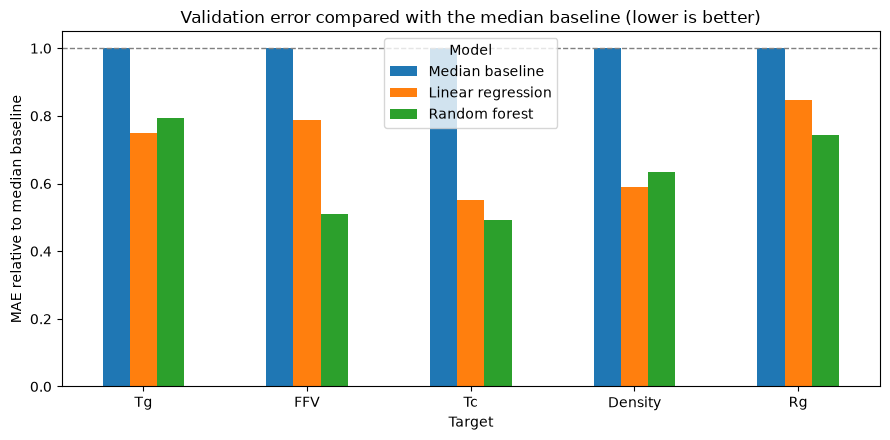

In [49]:
# Calculate the MAE relative to the median baseline for each target
baseline_mae = (
    results_df[results_df["model"] == "Median baseline"]
    .set_index("target")["MAE"]
)
results_df["relative_MAE"] = results_df["MAE"] / results_df["target"].map(baseline_mae)

# Display the relative MAE with targets as rows and models as columns
relative_mae_table = results_df.pivot(
    index="target", columns="model", values="relative_MAE"
).loc[target_columns, list(models)]

display(relative_mae_table.round(3))

# Plot the relative MAE for each target and model
ax = relative_mae_table.plot(kind="bar", figsize=(9, 4.5), rot=0)

ax.axhline(1.0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("MAE relative to median baseline")
ax.set_xlabel("Target")
ax.set_title("Validation error compared with the median baseline (lower is better)")
ax.legend(title="Model")

plt.tight_layout()
plt.show()

#### Findings: Model comparison

- Both machine learning models beat the median baseline for all five targets, so the nine descriptors contain useful information about every property.
- **Random forest** is best for **FFV** (MAE reduced by about 49%), **Tc** (about 51%) and **Rg** (about 26%).
- **Linear regression** is best for **Tg** (about 25%) and **Density** (about 41%).
- FFV is the only target where the random forest is clearly better than linear regression. FFV also has by far the most labels (5,624 training samples), and more complex models usually need more data.
- The other four targets have only about 100–150 validation samples each, so differences between the two models of a few percentage points may not be reliable. Cross-validation would give a more stable comparison.

### 20.6 Predicted vs. actual values (random forest)

Points on the diagonal line are perfect predictions.
Points far from the line are large errors.
A flat cloud of points means the model mostly predicts
values close to the average.

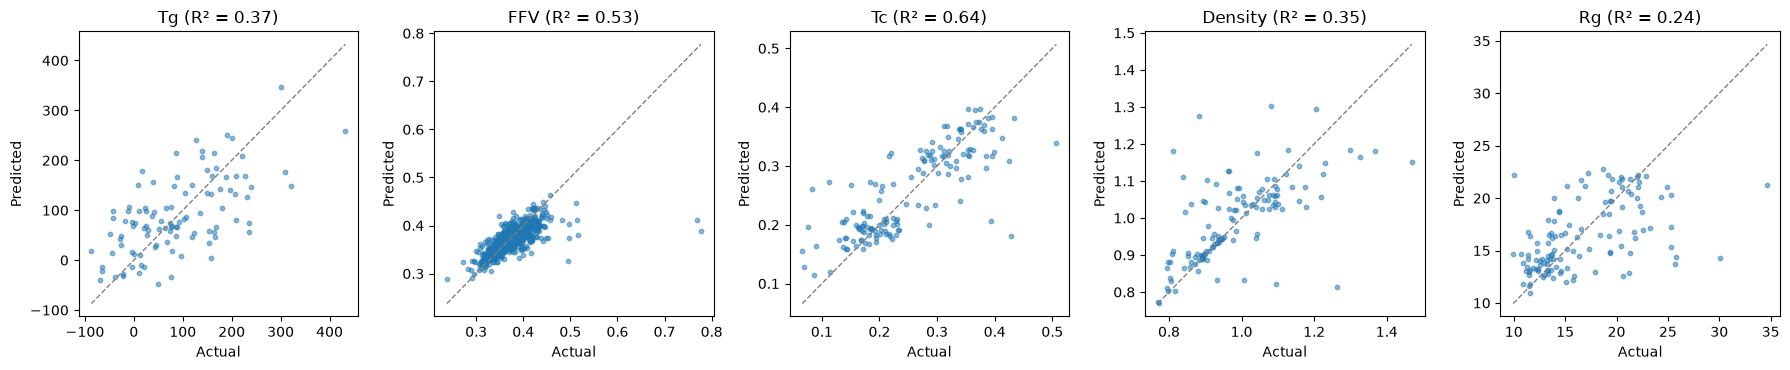

In [50]:
# Plot predicted vs. actual values of the random forest for each target
fig, axes = plt.subplots(1, len(target_columns), figsize=(18, 3.8))

for ax, target in zip(axes, target_columns):
    y_valid = modeling_splits[target]["y_valid"]
    y_pred = valid_predictions[(target, "Random forest")]

    ax.scatter(y_valid, y_pred, s=10, alpha=0.5)

    # Draw the diagonal line of perfect predictions
    limits = [min(y_valid.min(), y_pred.min()), max(y_valid.max(), y_pred.max())]
    ax.plot(limits, limits, color="grey", linestyle="--", linewidth=1)

    ax.set_title(f"{target} (R² = {r2_score(y_valid, y_pred):.2f})")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

plt.tight_layout()
plt.show()

#### Findings: Predicted vs. actual values

- **Tc** and **FFV** follow the diagonal most closely (R² of 0.64 and 0.53).
- For **Tg** and **Rg**, the points are widely scattered (R² of 0.37 and 0.24), so the predictions are only rough estimates.
- For all targets, the model **underestimates high values** and overestimates low values: the points are flatter than the diagonal. This is typical for random forests, which predict averages of training samples and cannot extrapolate beyond them.
- The two FFV samples with values around 0.77 are predicted at about 0.4. These match the extreme FFV values found during the EDA.

### 20.7 Feature importance (random forest)

The random forest records how much each descriptor reduces
the prediction error across all trees. A higher importance
means the model relies more on that descriptor.

Importance shows what the model uses, not what causes
the property. Correlated descriptors (for example MolWt,
HeavyAtomCount and NumAtoms) share their importance.

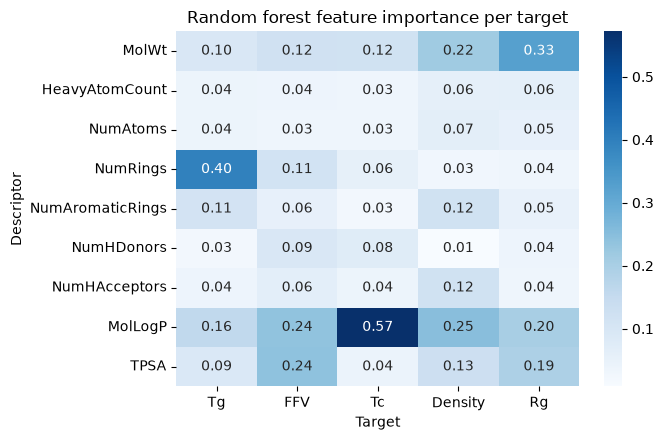

In [51]:
# Collect the random forest feature importances for each target
importance_df = pd.DataFrame(
    {
        target: trained_models[(target, "Random forest")].feature_importances_
        for target in target_columns
    },
    index=descriptor_columns,
)

# Plot the feature importances as a heatmap
plt.figure(figsize=(7, 4.5))
sns.heatmap(importance_df, annot=True, fmt=".2f", cmap="Blues")
plt.title("Random forest feature importance per target")
plt.xlabel("Target")
plt.ylabel("Descriptor")
plt.tight_layout()
plt.show()

#### Findings: Feature importance

- **MolLogP** is the most important descriptor for **Tc** (0.57) and is important for all targets.
- **NumRings** is the most important descriptor for **Tg** (0.40). This is chemically plausible: ring structures make polymer chains stiffer, which raises the glass transition temperature.
- **MolWt** is most important for **Rg** (0.33). This is also plausible, because the radius of gyration describes the size of the chain.
- **TPSA** and **MolLogP** dominate **FFV**. Both relate to polarity, which affects how tightly chains pack.
- `HeavyAtomCount` and `NumAtoms` have low importance, probably because they carry almost the same information as `MolWt`.

### 20.8 Decision: supplementary data are not used

Section 15 left the use of the supplementary datasets open.
A label comparison with the main training dataset showed:

| Dataset | Label | New structures | Comment |
|---|---|---:|---|
| dataset1 | Tc (`TC_mean`) | ~130 | The 737 overlapping structures have practically identical Tc values in train (99.6% exactly equal). Maximum TC_mean is 1.59, about three times the maximum Tc in train (0.52). |
| dataset2 | none | – | Structures only, no labels. |
| dataset3 | Tg | 46 | About +9% Tg labels. |
| dataset4 | FFV | 862 | FFV already has 7,030 labels. |

Decision: the models use the main training dataset only.

- The supplements add no labels for Density and Rg.
- They add only modest numbers of Tg and Tc labels.
- They come from older simulations, so their labels may
  not be fully comparable with the main dataset.
- Dataset 1 contains a Tc value far outside the training range.

### 20.9 Cross-validation

The comparison in 20.5 is based on a single validation split.
For Tg, Tc, Density and Rg, the validation subsets contain only
about 100–150 observations, so a single split can be lucky or unlucky.

With 5-fold cross-validation, the training subset is divided into
five parts (folds). Each model is trained five times, each time on
four folds and evaluated on the remaining fold. Every observation
is used for evaluation exactly once.

- The **mean** MAE over the five folds is a more stable estimate.
- The **standard deviation** shows how much the result depends on the split.

Cross-validation uses only the training subsets.
The validation subsets from section 19 remain untouched for
the final evaluation of the selected models.
All models use the same folds for a fair comparison.

In [52]:
from sklearn.model_selection import KFold, cross_val_score

# Use the same five folds for every model
N_FOLDS = 5
cv_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Store the MAE of every fold for each target and model
cv_rows = []

for target in target_columns:
    split = modeling_splits[target]

    for model_name, create_model in models.items():
        # scikit-learn returns negative MAE, so the sign is flipped
        fold_mae = -cross_val_score(
            create_model(),
            split["X_train"],
            split["y_train"],
            cv=cv_folds,
            scoring="neg_mean_absolute_error",
            n_jobs=-1,
        )

        cv_rows.append({
            "target": target,
            "model": model_name,
            "MAE_mean": fold_mae.mean(),
            "MAE_std": fold_mae.std(),
        })

cv_results_df = pd.DataFrame(cv_rows)

# Express the mean and standard deviation relative to the median baseline
cv_baseline_mae = (
    cv_results_df[cv_results_df["model"] == "Median baseline"]
    .set_index("target")["MAE_mean"]
)
cv_results_df["relative_MAE_mean"] = (
    cv_results_df["MAE_mean"] / cv_results_df["target"].map(cv_baseline_mae)
)
cv_results_df["relative_MAE_std"] = (
    cv_results_df["MAE_std"] / cv_results_df["target"].map(cv_baseline_mae)
)

display(cv_results_df.round(4))

,target,model,MAE_mean,MAE_std,relative_MAE_mean,relative_MAE_std
0,Tg,Median baseline,88.5952,2.6957,1.0000,0.0304
1,Tg,Linear regression,58.1458,5.6116,0.6563,0.0633
2,Tg,Random forest,61.9576,5.1994,0.6993,0.0587
3,FFV,Median baseline,0.0206,0.0004,1.0000,0.0186
4,FFV,Linear regression,0.0164,0.0005,0.7930,0.0252
5,FFV,Random forest,0.0109,0.0006,0.5283,0.0267
6,Tc,Median baseline,0.0754,0.0028,1.0000,0.0369
7,Tc,Linear regression,0.0444,0.0038,0.5892,0.0508
8,Tc,Random forest,0.0402,0.0034,0.5336,0.0451
9,Density,Median baseline,0.1045,0.0140,1.0000,0.1341


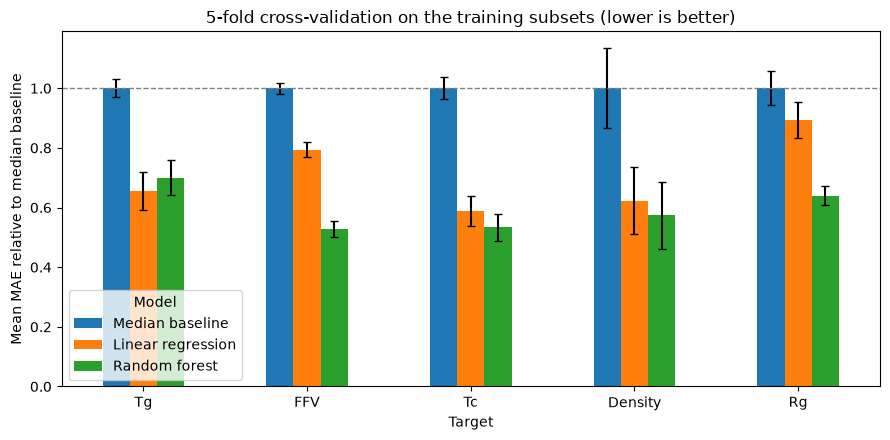

In [53]:
# Plot the mean relative MAE with the standard deviation as error bars
cv_mean_table = cv_results_df.pivot(
    index="target", columns="model", values="relative_MAE_mean"
).loc[target_columns, list(models)]
cv_std_table = cv_results_df.pivot(
    index="target", columns="model", values="relative_MAE_std"
).loc[target_columns, list(models)]

ax = cv_mean_table.plot(
    kind="bar", yerr=cv_std_table, capsize=3, figsize=(9, 4.5), rot=0
)

ax.axhline(1.0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Mean MAE relative to median baseline")
ax.set_xlabel("Target")
ax.set_title(f"{N_FOLDS}-fold cross-validation on the training subsets (lower is better)")
ax.legend(title="Model")

plt.tight_layout()
plt.show()

#### Findings: cross-validation

| Target | Linear regression | Random forest | Best model |
|---|---:|---:|---|
| Tg | 0.66 ± 0.06 | 0.70 ± 0.06 | No clear winner |
| FFV | 0.79 ± 0.03 | 0.53 ± 0.03 | Random forest |
| Tc | 0.59 ± 0.05 | 0.53 ± 0.05 | Random forest (small margin) |
| Density | 0.62 ± 0.11 | 0.57 ± 0.11 | No clear winner |
| Rg | 0.89 ± 0.06 | 0.64 ± 0.03 | Random forest |

Values are mean MAE relative to the median baseline ± standard deviation over five folds.

- Both models beat the baseline for every target in every
  comparison, so the descriptors carry real information.
- The random forest is clearly better for FFV and Rg.
- For Tg and Density, the differences are smaller than the
  variation between folds. Neither model is clearly better.
- For Density, the single split in 20.5 favoured linear regression,
  while cross-validation slightly favours the random forest.
  This confirms that a single small validation split can be misleading.
- Density has the largest variation between folds (± 0.11),
  so its results are the least certain.

### 20.10 Learning curves

A learning curve shows how the error changes when a model is
trained on more data. Each model is trained on 20%, 40%, 60%,
80% and 100% of the training folds and evaluated with the same
5-fold cross-validation as in 20.9.

How to read the curves:

- If the error is **still decreasing** at the largest training size,
  more labelled data would probably improve the model.
- If the error has **flattened**, more data of the same kind would
  help little. Improvements must then come from better features
  or models.

The dashed line shows the cross-validated median baseline.

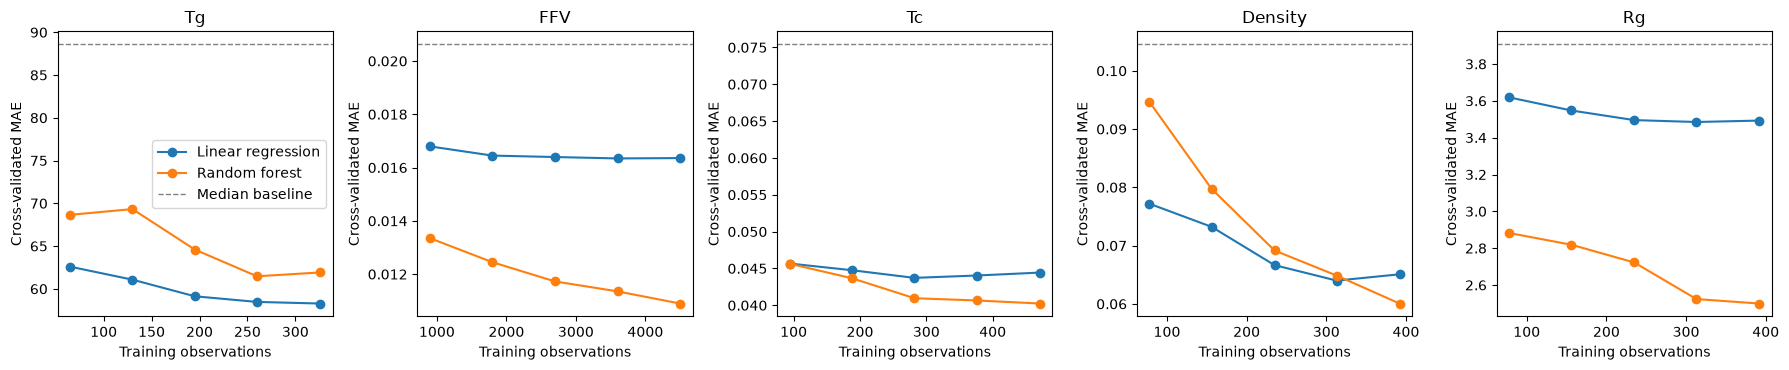

In [54]:
from sklearn.model_selection import learning_curve

# Train on 20%, 40%, ..., 100% of the training folds
TRAIN_SIZES = np.linspace(0.2, 1.0, 5)

fig, axes = plt.subplots(1, len(target_columns), figsize=(18, 3.8))

for ax, target in zip(axes, target_columns):
    split = modeling_splits[target]

    for model_name in ["Linear regression", "Random forest"]:
        train_sizes, _, valid_scores = learning_curve(
            models[model_name](),
            split["X_train"],
            split["y_train"],
            train_sizes=TRAIN_SIZES,
            cv=cv_folds,
            scoring="neg_mean_absolute_error",
            n_jobs=-1,
        )

        # Flip the sign to get MAE and average over the folds
        valid_mae = -valid_scores.mean(axis=1)
        ax.plot(train_sizes, valid_mae, marker="o", label=model_name)

    ax.axhline(cv_baseline_mae[target], color="grey", linestyle="--", linewidth=1,
               label="Median baseline")
    ax.set_title(target)
    ax.set_xlabel("Training observations")
    ax.set_ylabel("Cross-validated MAE")

axes[0].legend()
plt.tight_layout()
plt.show()

#### Findings: learning curves

| Target | Random forest curve | Interpretation |
|---|---|---|
| Tg | Decreases, then flattens around 260 observations | More data of the same kind would help little. Better features are more promising. |
| FFV | Still decreasing at 4,500 observations | More data would still help, even for the largest dataset. |
| Tc | Almost flat from about 280 observations | Limited by the nine descriptors rather than by the amount of data. |
| Density | Steeply decreasing, no plateau | More labelled data would probably help most here. |
| Rg | Still decreasing | More labelled data would probably help. |

- The linear regression curves are flat for most targets.
  A straight-line model with nine descriptors has reached its limit;
  more data alone will not improve it.
- **Answer to the data question:** the amount of data is sufficient
  to train useful models for all five targets (20.9).
  For Density and Rg, more labels would probably improve the models,
  but the supplementary datasets contain no labels for these targets.
  For Tc and Tg, where supplementary labels exist, the curves are
  nearly flat, so the supplements would likely add little.
  This supports the decision in 20.8.
- The next improvement should therefore focus on **richer features**
  (more RDKit descriptors or Morgan fingerprints).

### 20.11 XGBoost

XGBoost is a gradient boosting model. Like the random forest,
it combines many decision trees, but it builds them one after
another: each new tree focuses on correcting the errors of the
trees before it. Gradient boosting is often the strongest model
type for tabular data.

Boosting can overfit small datasets, so conservative settings
are used for all targets:

| Setting | Value | Meaning |
|---|---|---|
| `n_estimators` | 500 | Number of trees built one after another. |
| `learning_rate` | 0.05 | How strongly each tree corrects the previous ones. Smaller values learn more slowly but more carefully. |
| `max_depth` | 4 | Maximum depth of each tree. Shallow trees reduce overfitting. |
| `subsample` | 0.8 | Each tree sees a random 80% of the observations. |
| `colsample_bytree` | 0.8 | Each tree sees a random 80% of the descriptors. |

The settings are not tuned per target. XGBoost is evaluated
with the same 5-fold cross-validation as in 20.9.

In [55]:
from xgboost import XGBRegressor

# Define the XGBoost model
def create_xgboost():
    return XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


# Cross-validate XGBoost on the same folds as the other models
xgb_rows = []

for target in target_columns:
    split = modeling_splits[target]

    fold_mae = -cross_val_score(
        create_xgboost(),
        split["X_train"],
        split["y_train"],
        cv=cv_folds,
        scoring="neg_mean_absolute_error",
    )

    xgb_rows.append({
        "target": target,
        "model": "XGBoost",
        "MAE_mean": fold_mae.mean(),
        "MAE_std": fold_mae.std(),
        "relative_MAE_mean": fold_mae.mean() / cv_baseline_mae[target],
        "relative_MAE_std": fold_mae.std() / cv_baseline_mae[target],
    })

# Combine the XGBoost results with the results from 20.9
cv_results_df = pd.concat([cv_results_df, pd.DataFrame(xgb_rows)], ignore_index=True)

# Display the mean relative MAE of all models
all_model_names = [*models, "XGBoost"]

cv_mean_table = cv_results_df.pivot(
    index="target", columns="model", values="relative_MAE_mean"
).loc[target_columns, all_model_names]
cv_std_table = cv_results_df.pivot(
    index="target", columns="model", values="relative_MAE_std"
).loc[target_columns, all_model_names]

display(cv_mean_table.round(3))

model,Median baseline,Linear regression,Random forest,XGBoost
target,,,,
Tg,1.0,0.656,0.699,0.701
FFV,1.0,0.793,0.528,0.597
Tc,1.0,0.589,0.534,0.532
Density,1.0,0.622,0.574,0.520
Rg,1.0,0.893,0.640,0.643


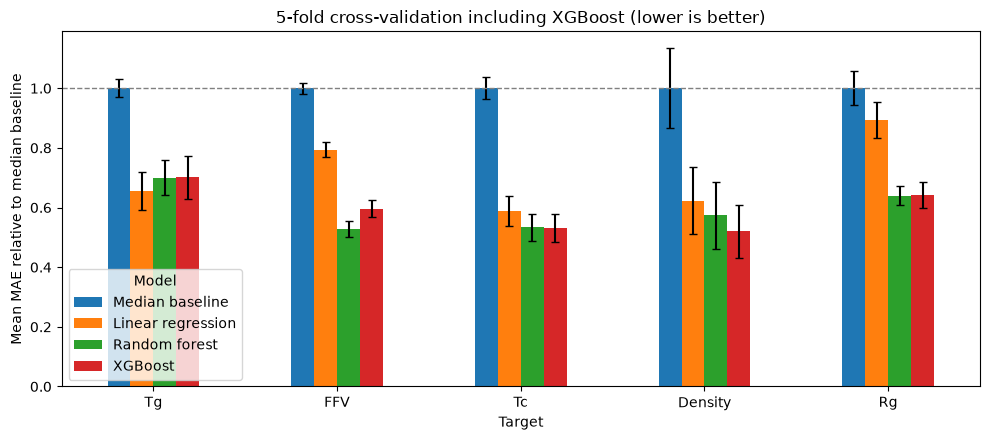

In [56]:
# Plot the mean relative MAE of all models with the standard deviation as error bars
ax = cv_mean_table.plot(
    kind="bar", yerr=cv_std_table, capsize=3, figsize=(10, 4.5), rot=0
)

ax.axhline(1.0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Mean MAE relative to median baseline")
ax.set_xlabel("Target")
ax.set_title(f"{N_FOLDS}-fold cross-validation including XGBoost (lower is better)")
ax.legend(title="Model")

plt.tight_layout()
plt.show()

#### Findings: XGBoost

Mean MAE relative to the median baseline (5-fold cross-validation):

| Target | Linear regression | Random forest | XGBoost |
|---|---:|---:|---:|
| Tg | **0.66** | 0.70 | 0.70 |
| FFV | 0.79 | **0.53** | 0.60 |
| Tc | 0.59 | 0.53 | 0.53 |
| Density | 0.62 | 0.57 | **0.52** |
| Rg | 0.89 | 0.64 | 0.64 |

- With untuned settings, XGBoost does **not** clearly outperform
  the random forest.
- It performs about the same for Tg, Tc and Rg.
- It has the lowest error for Density, but the difference is smaller
  than the variation between folds (about ± 0.11), so it is not reliable.
- It is clearly worse for FFV. With 4,500 training observations per fold,
  500 shallow trees with a small learning rate are probably too few
  to learn all the patterns (underfitting).
- XGBoost usually needs tuning to reach its full performance.
  Tuning the number of trees, learning rate and tree depth per target
  is a possible next step, but the learning curves (20.10) suggest that
  richer features are likely to bring a larger improvement.

### 20.12 Tuning XGBoost

The settings in 20.11 were the same for all targets.
Here, the settings are tuned separately for each target
with a randomized search:

1. Draw 30 random combinations of settings from the ranges below.
2. Evaluate each combination with the 5-fold cross-validation from 20.9
   on the training subset.
3. Keep the combination with the lowest mean MAE.

| Setting | Search range | Meaning |
|---|---|---|
| `n_estimators` | 200–1,500 | Number of trees. |
| `learning_rate` | 0.01–0.2 | How strongly each tree corrects the previous ones. |
| `max_depth` | 2–8 | Maximum depth of each tree. |
| `min_child_weight` | 1–10 | Minimum amount of data in a leaf. Higher values reduce overfitting. |
| `subsample` | 0.6–1.0 | Share of observations each tree sees. |
| `colsample_bytree` | 0.6–1.0 | Share of descriptors each tree sees. |
| `reg_lambda` | 0.1–10 | Penalty on large leaf values. Higher values reduce overfitting. |

The best cross-validation score is slightly optimistic, because the
same folds were used to choose the settings. The tuned models are
therefore also evaluated on the validation subsets from section 19,
which were not used for training or tuning.

In [57]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

# Define the search ranges for the XGBoost settings
xgb_search_space = {
    "n_estimators": randint(200, 1501),
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": randint(2, 9),
    "min_child_weight": randint(1, 11),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_lambda": loguniform(0.1, 10),
}

N_SEARCH_ITERATIONS = 30

# Tune XGBoost separately for each target
tuned_xgb_models = {}
tuning_rows = []

for target in target_columns:
    split = modeling_splits[target]

    search = RandomizedSearchCV(
        XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
        param_distributions=xgb_search_space,
        n_iter=N_SEARCH_ITERATIONS,
        scoring="neg_mean_absolute_error",
        cv=cv_folds,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    search.fit(split["X_train"], split["y_train"])

    # The search refits the best model on the complete training subset
    tuned_xgb_models[target] = search.best_estimator_

    tuning_rows.append({
        "target": target,
        "relative_MAE_mean": -search.best_score_ / cv_baseline_mae[target],
        **search.best_params_,
    })

tuning_df = pd.DataFrame(tuning_rows).set_index("target")

display(tuning_df.round(3))

,relative_MAE_mean,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample
target,,,,,,,,
Tg,0.655,0.764,0.011,2,1,1353,1.153,0.779
FFV,0.534,0.914,0.018,8,4,1031,0.858,0.944
Tc,0.512,0.722,0.013,5,7,708,4.639,0.669
Density,0.527,0.688,0.053,5,1,641,8.412,0.701
Rg,0.641,0.837,0.023,4,1,812,8.779,0.940


#### Findings: tuned settings

Best mean cross-validated MAE relative to the median baseline
(slightly optimistic, see above), compared with 20.11:

| Target | XGBoost (20.11) | XGBoost (tuned) |
|---|---:|---:|
| Tg | 0.70 | 0.66 |
| FFV | 0.60 | 0.53 |
| Tc | 0.53 | 0.51 |
| Density | 0.52 | 0.53 |
| Rg | 0.64 | 0.64 |

- Tuning helped most for FFV, the largest dataset. The best settings
  use deep trees (`max_depth` = 8) and about 1,000 trees, confirming
  that the default settings in 20.11 were too simple for FFV.
- For Tg, the search chose very shallow trees (`max_depth` = 2) and a
  small learning rate. This is a nearly linear model, which matches the
  good performance of linear regression for Tg.
- For Density and Rg, strong regularisation (`reg_lambda` above 8) was
  selected, which is typical for small datasets.
- For Density and Rg, tuning brought no improvement.

#### Comparison on the validation subsets

All models are now evaluated on the same validation subsets
from section 19. The results for the median baseline, linear
regression and random forest come from 20.4. The untuned and
tuned XGBoost models are trained on the complete training subset.

model,Median baseline,Linear regression,Random forest,XGBoost,XGBoost (tuned)
target,,,,,
Tg,1.0,0.748,0.795,0.790,0.744
FFV,1.0,0.788,0.510,0.583,0.517
Tc,1.0,0.550,0.491,0.461,0.476
Density,1.0,0.589,0.633,0.530,0.540
Rg,1.0,0.846,0.743,0.731,0.715


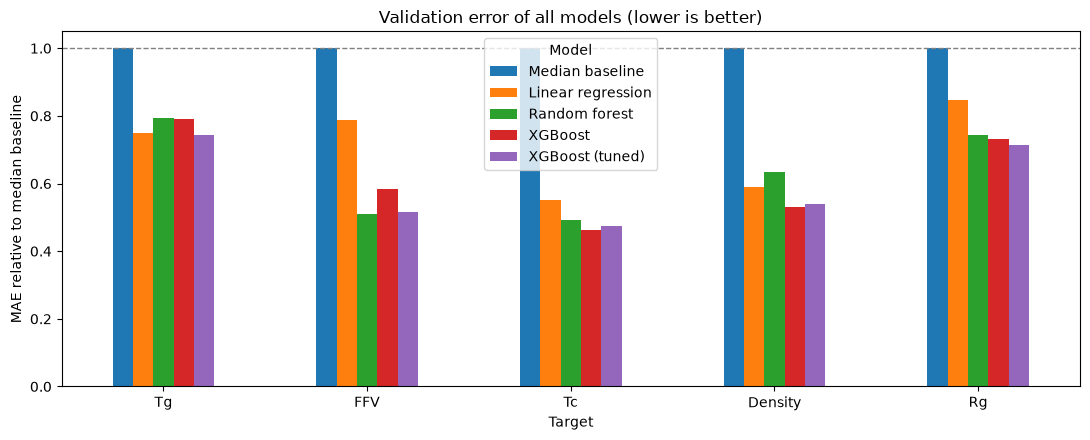

In [58]:
# Evaluate the untuned and tuned XGBoost models on the validation subsets
xgb_valid_rows = []

for target in target_columns:
    split = modeling_splits[target]

    untuned_model = create_xgboost()
    untuned_model.fit(split["X_train"], split["y_train"])

    for model_name, model in [
        ("XGBoost", untuned_model),
        ("XGBoost (tuned)", tuned_xgb_models[target]),
    ]:
        y_pred = model.predict(split["X_valid"])
        scores = evaluate_model(split["y_valid"], y_pred)
        xgb_valid_rows.append({"target": target, "model": model_name, **scores})

# Combine with the validation results from 20.4
valid_results_df = pd.concat([results_df, pd.DataFrame(xgb_valid_rows)], ignore_index=True)
valid_results_df["relative_MAE"] = (
    valid_results_df["MAE"] / valid_results_df["target"].map(baseline_mae)
)

# Display the relative MAE on the validation subsets
valid_model_names = [*models, "XGBoost", "XGBoost (tuned)"]

valid_relative_mae_table = valid_results_df.pivot(
    index="target", columns="model", values="relative_MAE"
).loc[target_columns, valid_model_names]

display(valid_relative_mae_table.round(3))

# Plot the relative MAE on the validation subsets
ax = valid_relative_mae_table.plot(kind="bar", figsize=(11, 4.5), rot=0)

ax.axhline(1.0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("MAE relative to median baseline")
ax.set_xlabel("Target")
ax.set_title("Validation error of all models (lower is better)")
ax.legend(title="Model")

plt.tight_layout()
plt.show()

#### Findings: validation comparison

MAE relative to the median baseline on the validation subsets:

| Target | Linear regression | Random forest | XGBoost | XGBoost (tuned) |
|---|---:|---:|---:|---:|
| Tg | 0.75 | 0.80 | 0.79 | **0.74** |
| FFV | 0.79 | **0.51** | 0.58 | 0.52 |
| Tc | 0.55 | 0.49 | **0.46** | 0.48 |
| Density | 0.59 | 0.63 | **0.53** | 0.54 |
| Rg | 0.85 | 0.74 | 0.73 | **0.72** |

- The tuned XGBoost is the best or within about 0.02 of the best
  model for every target. It is the most consistent single model.
- Tuning mainly fixed the FFV result (0.58 → 0.52), which now matches
  the random forest.
- For Tc and Density, the untuned XGBoost was already as good as the
  tuned one. The small differences are within the expected variation.
- For Density, both XGBoost models are clearly better than the random
  forest on this split (0.53–0.54 vs. 0.63). Cross-validation showed
  a smaller gap, so the true advantage is probably smaller.
- Overall, the improvement over the random forest is modest.
  With nine descriptors, the choice of model matters less than
  the information contained in the features.

**Decision:** the tuned XGBoost is selected as the main model for
all five targets. The next step is to test richer features.